Ссылка на датасет (train и test): https://drive.google.com/drive/folders/1bzVQHEY92brgmM7Ysd5OMwcG3V2lCzr8?usp=sharing, https://drive.google.com/drive/folders/1J9X-Iu2prlCqwzEmcWSjHM2LLE2mG-Vm?usp=sharing

Ссылка на чекпоинты: https://drive.google.com/drive/folders/1bzVQHEY92brgmM7Ysd5OMwcG3V2lCzr8?usp=sharing

In [ ]:
import os
from google.colab import drive

drive.mount('/content/drive')

BASE_DIR = "/content/drive/MyDrive"
TRAIN_DIR = os.path.join(BASE_DIR, "DATA")
TEST_DIR = os.path.join(BASE_DIR, "TEST")

if not os.path.exists(TRAIN_DIR) or not os.path.exists(TEST_DIR):
    raise FileNotFoundError("Папки DATA или TEST не найдены в корне Диска")

CHECKPOINT_DIR = os.path.join(BASE_DIR, "traffic_signs_checkpoints")
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

print(f"Тренировочные данные: {TRAIN_DIR}")
print(f"Тестовые данные: {TEST_DIR}")

Mounted at /content/drive
Тренировочные данные: /content/drive/MyDrive/DATA
Тестовые данные: /content/drive/MyDrive/TEST


In [ ]:
import time
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from collections import Counter

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset, WeightedRandomSampler
from torchvision import transforms, models, datasets
from sklearn.metrics import balanced_accuracy_score, f1_score, confusion_matrix

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

BATCH_SIZE = 64
EPOCHS_BASE = 25
EPOCHS_AT = 20
LR_HEAD = 3e-4
LR_L4 = 1e-4 # layer4
LR_L3 = 3e-5 # layer3
WEIGHT_DECAY = 1e-4
IMG_SIZE = 224

Device: cuda


In [ ]:
import torchvision.transforms.functional as TF

class PhysicalAugmentation:
    def __call__(self, img):
        # окклюзия 30%
        if random.random() < 0.3:
            w, h = img.size
            box = 24
            top  = random.randint(0, h - box)
            left = random.randint(0, w - box)
            img = TF.to_tensor(img)
            img[:, top:top+box, left:left+box] = 0.5
            img = TF.to_pil_image(img)

        # масштаб 30%
        if random.random() < 0.3:
            w, h = img.size
            scale = random.uniform(0.75, 1.0)
            new_w, new_h = int(w * scale), int(h * scale)
            img = TF.resize(img, (new_h, new_w))
            pad_w, pad_h = w - new_w, h - new_h
            img = TF.pad(img, (pad_w//2, pad_h//2, pad_w - pad_w//2, pad_h - pad_h//2), fill=128)
            img = TF.resize(img, (h, w))

        # блюр 15%
        if random.random() < 0.15:
            img = TF.gaussian_blur(img, kernel_size=3)

        # шум 15%
        if random.random() < 0.15:
            img = TF.to_tensor(img)
            img = img + torch.randn_like(img) * 0.05
            img = torch.clamp(img, 0, 1)
            img = TF.to_pil_image(img)

        return img


train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    PhysicalAugmentation(),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.3, contrast=0.3),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

val_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# основной датасет с аугментациями
full_train_dataset = datasets.ImageFolder(root=TRAIN_DIR, transform=train_tf)
# чистый датасет без аугментаций
full_train_clean = datasets.ImageFolder(root=TRAIN_DIR, transform=val_tf)
val_dataset = datasets.ImageFolder(root=TEST_DIR, transform=val_tf)

NUM_CLASSES = len(full_train_dataset.classes)
print(f"Найдено классов: {NUM_CLASSES}")
print(f"Тренировочных изображений: {len(full_train_dataset)}")
print(f"Тестовых изображений: {len(val_dataset)}")

# сплит 80/20
train_size = int(0.8 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size
generator = torch.Generator().manual_seed(SEED)

train_dataset, internal_val_aug = torch.utils.data.random_split(full_train_dataset, [train_size, val_size], generator=generator)
# тот же сплит поверх чистого датасета
internal_val_clean = Subset(full_train_clean, internal_val_aug.indices)

# подсчет баланса и веса по train-сплиту
train_labels = [full_train_dataset.samples[i][1] for i in train_dataset.indices]
cnt_tr = Counter(train_labels)
train_counts_tr = np.array([cnt_tr.get(i, 0) for i in range(NUM_CLASSES)])

print(f"\nTrain-сплит: {len(train_dataset)} примеров")
print(f"Min/Max/Mean count: {train_counts_tr.min()} / {train_counts_tr.max()} / {train_counts_tr.mean():.1f}")
print(f"Max/Min ratio: {train_counts_tr.max() / max(train_counts_tr.min(),1):.2f}")

sample_w = np.array([1.0 / np.sqrt(train_counts_tr[label]) for label in train_labels])
sample_w = sample_w / sample_w.sum()
sampler = WeightedRandomSampler(weights=torch.tensor(sample_w, dtype=torch.double), num_samples=len(sample_w), replacement=True,)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, sampler=sampler, num_workers=0, pin_memory=True)
internal_val_loader = DataLoader(internal_val_clean, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

print(f"\nInternal val (из train): {len(internal_val_clean)} примеров")
print(f"Test: {len(val_dataset)} примеров")

Найдено классов: 52
Тренировочных изображений: 5683
Тестовых изображений: 433

Train-сплит: 4546 примеров
Min/Max/Mean count: 13 / 400 / 87.4
Max/Min ratio: 30.77

Internal val (из train): 1137 примеров
Test: 433 примеров


In [ ]:
def build_model(num_classes):
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

    # замораживаем все
    for p in model.parameters():
        p.requires_grad = False

    # размораживаем layer3 и layer4
    for name, p in model.named_parameters():
        if name.startswith("layer3") or name.startswith("layer4"):
            p.requires_grad = True

    # новая голова
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    nn.init.normal_(model.fc.weight, 0, 0.01)
    nn.init.zeros_(model.fc.bias)

    return model.to(DEVICE)


def build_optimizer(model, wd=WEIGHT_DECAY):
    return optim.AdamW([
        {"params": model.layer3.parameters(), "lr": LR_L3, "weight_decay": wd},
        {"params": model.layer4.parameters(), "lr": LR_L4, "weight_decay": wd},
        {"params": model.fc.parameters(), "lr": LR_HEAD, "weight_decay": wd},
    ])


# лосс с весами классов
w = 1.0 / np.sqrt(train_counts_tr.astype(np.float64))
w = w / w.mean()
class_weights = torch.tensor(w, dtype=torch.float).to(DEVICE)
criterion = nn.CrossEntropyLoss(weight=class_weights)


def set_bn_eval(module):
    if isinstance(module, nn.BatchNorm2d):
        module.eval()


# оценка с тремя метриками
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    ys, ps = [], []
    for x, y in loader:
        x = x.to(DEVICE)
        ps.extend(model(x).argmax(1).cpu().numpy())
        ys.extend(y.numpy())
    ys, ps = np.array(ys), np.array(ps)
    return {
        "acc": float((ys == ps).mean()),
        "bal_acc": float(balanced_accuracy_score(ys, ps)),
        "macro_f1": float(f1_score(ys, ps, average="macro", zero_division=0)),
        "per_class": confusion_matrix(ys, ps, labels=list(range(NUM_CLASSES))),
    }


# атаки
def fgsm_attack(model, x, y, epsilon, criterion):
    model.eval()
    x = x.clone().detach().to(DEVICE); x.requires_grad = True
    y = y.to(DEVICE)
    outputs = model(x)
    loss = criterion(outputs, y)
    model.zero_grad()
    loss.backward()
    x_adv = (x + epsilon * x.grad.data.sign()).clamp(-2.5, 2.5)
    return x_adv.detach()


def pgd_attack(model, x, y, epsilon=0.03, alpha=0.01, num_iter=10, criterion=criterion, random_start=True):
    model.eval()
    x0 = x.clone().detach().to(DEVICE)
    y = y.to(DEVICE)
    lo, hi = -2.5, 2.5
    if random_start:
        delta = torch.empty_like(x0).uniform_(-epsilon, epsilon)
    else:
        delta = torch.zeros_like(x0)
    delta = torch.clamp(x0 + delta, lo, hi) - x0
    for _ in range(num_iter):
        delta.requires_grad_(True)
        loss = criterion(model(x0 + delta), y)
        grad = torch.autograd.grad(loss, delta)[0]
        delta = delta.detach() + alpha * grad.sign()
        delta = torch.clamp(delta, -epsilon, epsilon)
        delta = torch.clamp(x0 + delta, lo, hi) - x0
    return (x0 + delta).detach()


def eot_pgd_attack(model, x, y, epsilon=0.03, alpha=0.01, num_iter=10, num_noise_samples=10, sigma=0.25, criterion=criterion, random_start=True):
    model.eval()
    x0 = x.clone().detach().to(DEVICE)
    y = y.to(DEVICE)
    lo, hi = -2.5, 2.5

    if random_start:
        delta = torch.empty_like(x0).uniform_(-epsilon, epsilon)
    else:
        delta = torch.zeros_like(x0)
    delta = torch.clamp(x0 + delta, lo, hi) - x0

    for _ in range(num_iter):
        delta.requires_grad_(True)

        loss_avg = 0.0
        for _ in range(num_noise_samples):
            noise = torch.randn_like(x0) * sigma
            noisy_input = x0 + delta + noise
            output = model(noisy_input)
            loss_avg = loss_avg + criterion(output, y)
        loss_avg = loss_avg / num_noise_samples

        grad = torch.autograd.grad(loss_avg, delta)[0]
        delta = delta.detach() + alpha * grad.sign()
        delta = torch.clamp(delta, -epsilon, epsilon)
        delta = torch.clamp(x0 + delta, lo, hi) - x0

    return (x0 + delta).detach()


def evaluate_asr(model, loader, attack_fn, epsilon, **kw):
    model.eval()
    total, clean_ok, attacked, success = 0, 0, 0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.no_grad():
            pred = model(x).argmax(1)
        mask = pred == y
        clean_ok += mask.sum().item(); total += y.size(0)
        if mask.any():
            x_ok, y_ok = x[mask], y[mask]
            x_adv = attack_fn(model, x_ok, y_ok, epsilon, **kw)
            with torch.no_grad():
                pred_adv = model(x_adv).argmax(1)
            success  += (pred_adv != y_ok).sum().item()
            attacked += y_ok.size(0)
    return clean_ok / total, success / attacked if attacked else 0.0

In [ ]:
import os
import numpy as np
import torch
import torch.optim as optim
from tqdm.auto import tqdm

def train_baseline(model, train_loader, val_loader_internal, epochs=EPOCHS_BASE, patience=6):
    optimizer = build_optimizer(model)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    history = {"loss": [], "train_acc": [], "val_acc": [], "val_bal_acc": [], "val_macro_f1": []}
    best_val, best_state, bad = 0.0, None, 0
    start_epoch = 0

    best_path = os.path.join(CHECKPOINT_DIR, "baseline_best.pth")
    last_path = os.path.join(CHECKPOINT_DIR, "baseline_last.pth")

    resumed = False
    resume_ckpt = None
    if os.path.exists(last_path):
        resume_ckpt = torch.load(last_path, map_location=DEVICE)
        resumed = True
    elif os.path.exists(best_path):
        resume_ckpt = torch.load(best_path, map_location=DEVICE)
        resumed = True

    if resumed:
        ck = resume_ckpt
        model.load_state_dict(ck['model_state_dict'])

        if 'optimizer_state_dict' in ck:
            try:
                optimizer.load_state_dict(ck['optimizer_state_dict'])
            except Exception:
                pass

        if 'scheduler_state_dict' in ck:
            try:
                scheduler.load_state_dict(ck['scheduler_state_dict'])
            except Exception:
                pass

        start_epoch = ck.get('epoch', len(ck.get('history', {}).get('loss', [])) - 1) + 1
        history = ck.get('history', history)
        best_val = ck.get('best_val', 0.0)

        if os.path.exists(best_path):
            ck_best = torch.load(best_path, map_location=DEVICE)
            best_state = {k: v.detach().clone()
                          for k, v in ck_best['model_state_dict'].items()}
            best_val = ck_best.get('best_val', best_val)
        else:
            best_state = {k: v.detach().clone()
                          for k, v in model.state_dict().items()}

        if len(history.get("loss", [])) > 0:
            print("История обучения из чекпоинта:")
            print(f"{'Epoch':>5} | {'loss':>8} | {'train_acc':>10} | "f"{'val_acc':>8} | {'val_bal':>8} | {'val_f1':>8}")
            print("-" * 64)
            for i in range(len(history["loss"])):
                print(f"{i+1:>5} | {history['loss'][i]:>8.4f} | "
                      f"{history['train_acc'][i]:>10.4f} | "
                      f"{history['val_acc'][i]:>8.4f} | "
                      f"{history['val_bal_acc'][i]:>8.4f} | "
                      f"{history['val_macro_f1'][i]:>8.4f}")
            best_ep = int(np.argmax(history["val_bal_acc"])) + 1
            print(f"\nЛучшая эпоха по val_bal_acc: {best_ep} "f"(val_bal_acc={max(history['val_bal_acc']):.4f})")

    for epoch in range(start_epoch, epochs):
        model.train()
        model.apply(set_bn_eval)

        running_loss, correct, total = 0.0, 0, 0
        pbar = tqdm(train_loader, desc=f"Baseline {epoch+1}/{epochs}", leave=False)
        for x, y in pbar:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                [p for p in model.parameters() if p.requires_grad], max_norm=1.0)
            optimizer.step()

            running_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += y.size(0)
            pbar.set_postfix(loss=f"{loss.item():.3f}", acc=f"{correct/total:.3f}")

        scheduler.step()
        tr_loss = running_loss / total
        tr_acc  = correct / total
        vm = evaluate(model, val_loader_internal)

        history["loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)
        history["val_acc"].append(vm["acc"])
        history["val_bal_acc"].append(vm["bal_acc"])
        history["val_macro_f1"].append(vm["macro_f1"])

        print(f"Epoch {epoch+1:02d} | loss {tr_loss:.4f} | train {tr_acc:.4f} | "
              f"val_acc {vm['acc']:.4f} | val_bal {vm['bal_acc']:.4f} | "
              f"val_f1 {vm['macro_f1']:.4f}")

        improved = vm["bal_acc"] > best_val + 1e-4
        if improved:
            best_val = vm["bal_acc"]
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            bad = 0
            torch.save({
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'scheduler_state_dict': scheduler.state_dict(),
                'history': history,
                'best_val': best_val,
            }, best_path)
        else:
            bad += 1

        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': scheduler.state_dict(),
            'history': history,
            'best_val': best_val,
        }, last_path)

        if bad >= patience:
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    torch.save({
        'epoch': len(history['loss']) - 1,
        'model_state_dict': model.state_dict(),
        'history': history,
        'best_val': best_val,
    }, last_path)

    final_path = os.path.join(CHECKPOINT_DIR, "baseline_final.pth")
    torch.save({
        'model_state_dict': model.state_dict(),
        'best_val': best_val,
        'history': history,
        'config': {
            'arch': 'resnet18',
            'num_classes': NUM_CLASSES,
            'epochs': epochs,
            'patience': patience,
            'lr_head': LR_HEAD, 'lr_l4': LR_L4, 'lr_l3': LR_L3,
            'weight_decay': WEIGHT_DECAY,
            'img_size': IMG_SIZE,
            'batch_size': BATCH_SIZE,
        },
    }, final_path)

    return history


best_path = os.path.join(CHECKPOINT_DIR, "baseline_best.pth")
last_path = os.path.join(CHECKPOINT_DIR, "baseline_last.pth")

epochs_eff = EPOCHS_BASE
if os.path.exists(last_path):
    try:
        _ck = torch.load(last_path, map_location="cpu")
        _last_ep = _ck.get("epoch", len(_ck.get("history", {}).get("loss", [])) - 1)
        epochs_eff = _last_ep + 1
    except Exception:
        pass
elif os.path.exists(best_path):
    try:
        _ck = torch.load(best_path, map_location="cpu")
        _last_ep = _ck.get("epoch", len(_ck.get("history", {}).get("loss", [])) - 1)
        epochs_eff = _last_ep + 1
    except Exception:
        pass

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=sampler,
    num_workers=0,
    pin_memory=True,
    generator=torch.Generator().manual_seed(SEED),
)

# запуск
baseline_model = build_model(NUM_CLASSES)
baseline_history = train_baseline(
    baseline_model, train_loader, internal_val_loader,
    epochs=epochs_eff, patience=6,
)

n_epochs = len(baseline_history["loss"])
best_bal = max(baseline_history["val_bal_acc"]) if n_epochs > 0 else 0.0

# тест
tm = evaluate(baseline_model, val_loader)
print(f"\nbaseline test")
print(f"acc={tm['acc']:.4f} | bal_acc={tm['bal_acc']:.4f} | macro_f1={tm['macro_f1']:.4f}")
baseline_clean_acc = tm["acc"]
baseline_clean_bal_acc = tm["bal_acc"]

# атаки
print("\nАтаки на baseline (eps=0.03)")
_, asr_fgsm_base = evaluate_asr(baseline_model, val_loader, fgsm_attack, 0.03, criterion=criterion)
_, asr_pgd_base  = evaluate_asr(baseline_model, val_loader, pgd_attack, 0.03, alpha=0.01, num_iter=10, criterion=criterion)
print(f"FGSM ASR: {asr_fgsm_base:.4f}")
print(f"PGD ASR: {asr_pgd_base:.4f}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 117MB/s]


История обучения из чекпоинта:
Epoch |     loss |  train_acc |  val_acc |  val_bal |   val_f1
----------------------------------------------------------------
    1 |   1.9704 |     0.4925 |   0.8021 |   0.7273 |   0.6727
    2 |   0.4624 |     0.8537 |   0.9120 |   0.8559 |   0.8469
    3 |   0.2335 |     0.9261 |   0.9560 |   0.9169 |   0.9151
    4 |   0.1565 |     0.9523 |   0.9261 |   0.8962 |   0.8938
    5 |   0.1230 |     0.9657 |   0.9367 |   0.9063 |   0.9016
    6 |   0.0808 |     0.9721 |   0.9675 |   0.9495 |   0.9442
    7 |   0.0701 |     0.9745 |   0.9507 |   0.9347 |   0.9361
    8 |   0.0621 |     0.9824 |   0.9763 |   0.9466 |   0.9501
    9 |   0.0528 |     0.9846 |   0.9736 |   0.9494 |   0.9480
   10 |   0.0410 |     0.9881 |   0.9842 |   0.9606 |   0.9615
   11 |   0.0404 |     0.9872 |   0.9842 |   0.9657 |   0.9663
   12 |   0.0211 |     0.9914 |   0.9877 |   0.9708 |   0.9707
   13 |   0.0251 |     0.9930 |   0.9859 |   0.9710 |   0.9665
   14 |   0.0155 |    

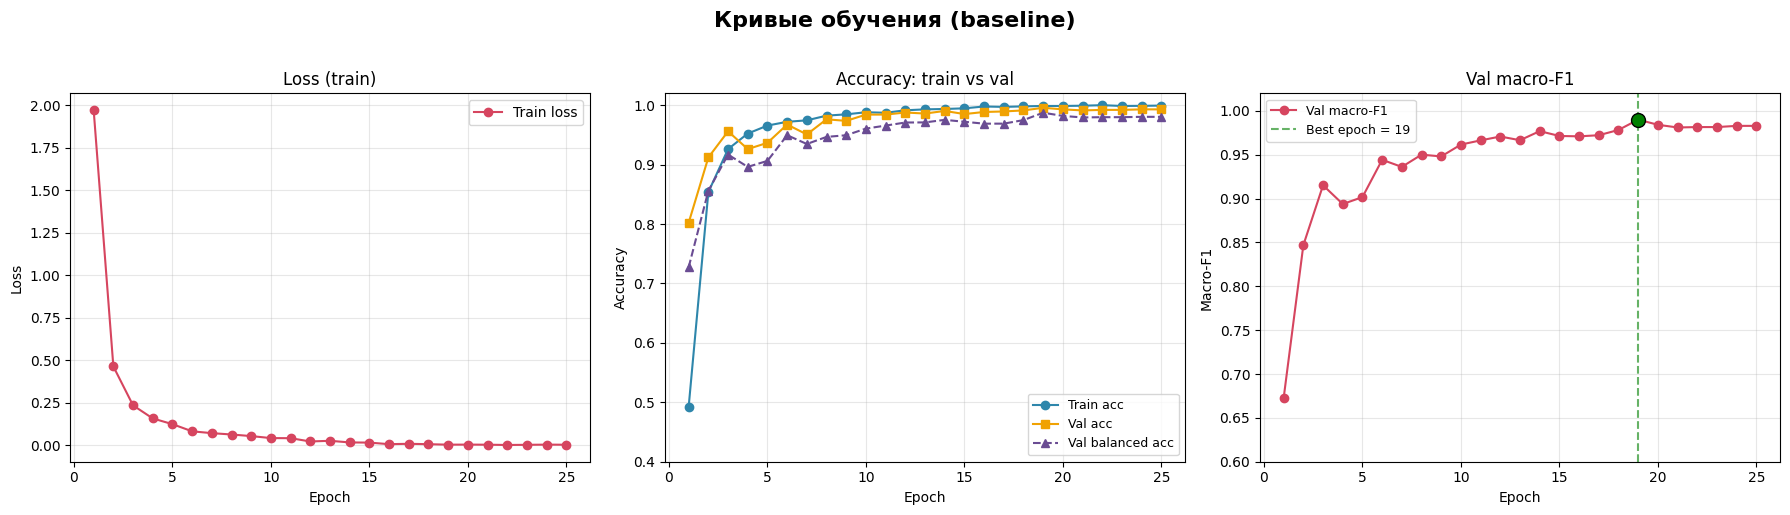

In [ ]:
# кривые обучения baseline
import matplotlib.pyplot as plt
import numpy as np

h = baseline_history
epochs = np.arange(1, len(h["loss"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Кривые обучения (baseline)", fontsize=16, fontweight="bold", y=1.02)

# loss
axes[0].plot(epochs, h["loss"], "o-", color="#D6455F", label="Train loss")
axes[0].set_title("Loss (train)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(alpha=0.3)
axes[0].legend()

# train acc против val acc
axes[1].plot(epochs, h["train_acc"], "o-", color="#2E86AB", label="Train acc")
axes[1].plot(epochs, h["val_acc"], "s-", color="#F0A202", label="Val acc")
axes[1].plot(epochs, h["val_bal_acc"], "^--", color="#6A4C93", label="Val balanced acc")
axes[1].set_title("Accuracy: train vs val")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0.4, 1.02)
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=9)

# val F1 + отметка best
axes[2].plot(epochs, h["val_macro_f1"], "o-", color="#D6455F", label="Val macro-F1")
best_ep = int(np.argmax(h["val_bal_acc"])) + 1
best_val = max(h["val_bal_acc"])
axes[2].axvline(best_ep, ls="--", color="green", alpha=0.6, label=f"Best epoch = {best_ep}")
axes[2].scatter([best_ep], [h["val_macro_f1"][best_ep - 1]], color="green", s=100, zorder=5, edgecolor="k")
axes[2].set_title("Val macro-F1")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Macro-F1")
axes[2].set_ylim(0.6, 1.02)
axes[2].grid(alpha=0.3)
axes[2].legend(fontsize=9)

plt.tight_layout()
plt.show()

In [ ]:
def at_loss(clean_logits, adv_logits, y, weight=0.5):
    ce_clean = F.cross_entropy(clean_logits, y, weight=class_weights)
    ce_adv   = F.cross_entropy(adv_logits,   y, weight=class_weights)
    return (1 - weight) * ce_clean + weight * ce_adv

def train_adversarial_warmup(model, train_loader, val_loader, epochs_total=15, patience=6, epsilon=0.03, alpha=0.01, num_iter=10, adv_weight=0.5):
    optimizer = build_optimizer(model)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs_total)

    history = {"loss": [], "train_acc": [], "val_f1": []}
    best_f1, best_state, bad = 0.0, None, 0
    start_epoch = 0

    best_path = os.path.join(CHECKPOINT_DIR, "defended_best.pth")
    last_path = os.path.join(CHECKPOINT_DIR, "defended_last.pth")

    resumed = False
    resume_ckpt = None
    if os.path.exists(last_path):
        resume_ckpt = torch.load(last_path, map_location=DEVICE)
        resumed = True
    elif os.path.exists(best_path):
        resume_ckpt = torch.load(best_path, map_location=DEVICE)
        resumed = True

    if resumed:
        ck = resume_ckpt
        model.load_state_dict(ck['model_state_dict'])
        if 'optimizer_state_dict' in ck:
            try:
                optimizer.load_state_dict(ck['optimizer_state_dict'])
            except Exception:
                pass
        if 'scheduler_state_dict' in ck:
            try:
                scheduler.load_state_dict(ck['scheduler_state_dict'])
            except Exception:
                pass

        start_epoch = ck['epoch'] + 1 if 'epoch' in ck else len(ck['history']['loss'])
        history = ck['history']
        best_f1 = ck.get('best_val', ck.get('best_f1', 0.0))

        if os.path.exists(best_path):
            ck_best = torch.load(best_path, map_location=DEVICE)
            best_state = {k: v.detach().clone()
                          for k, v in ck_best['model_state_dict'].items()}
            best_f1 = ck_best.get('best_val', ck_best.get('best_f1', best_f1))
        else:
            best_state = {k: v.detach().clone()
                          for k, v in model.state_dict().items()}

        # вывод истории по эпохам
        if len(history["loss"]) > 0:
            print(f"{'Epoch':>5} | {'loss':>8} | {'train_acc':>10} | {'val_f1':>8}")
            print("-" * 42)
            for i in range(len(history["loss"])):
                print(f"{i+1:>5} | {history['loss'][i]:>8.4f} | "
                      f"{history['train_acc'][i]:>10.4f} | "
                      f"{history['val_f1'][i]:>8.4f}")
            best_ep = int(np.argmax(history["val_f1"])) + 1
            print(f"\nЛучшая эпоха по val_f1: {best_ep} "f"(val_f1={max(history['val_f1']):.4f})")

    # цикл обучения
    for epoch in range(start_epoch, epochs_total):
        use_fgsm = epoch < 3
        model.train(); model.apply(set_bn_eval)

        running_loss, correct, total = 0.0, 0, 0
        tag = "FGSM" if use_fgsm else "PGD"
        pbar = tqdm(train_loader, desc=f"AT {epoch+1}/{epochs_total} ({tag})", leave=False)

        for x, y in pbar:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()

            if use_fgsm:
                adv_x = fgsm_attack(model, x, y, epsilon, criterion)
            else:
                adv_x = pgd_attack(model, x, y, epsilon, alpha, num_iter, criterion)

            model.train(); model.apply(set_bn_eval)
            logits_clean = model(x)
            logits_adv = model(adv_x)
            loss = at_loss(logits_clean, logits_adv, y, weight=adv_weight)
            loss.backward()
            torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 1.0)
            optimizer.step()

            running_loss += loss.item() * x.size(0)
            correct += (logits_clean.argmax(1) == y).sum().item()
            total += y.size(0)
            pbar.set_postfix(loss=f"{loss.item():.3f}", acc=f"{correct/total:.3f}")

        scheduler.step()
        tr_loss, tr_acc = running_loss / total, correct / total

        val_metrics = evaluate(model, val_loader)
        val_f1 = val_metrics["macro_f1"] if isinstance(val_metrics, dict) else float(val_metrics)

        history["loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)
        history["val_f1"].append(val_f1)
        print(f"AT Epoch {epoch+1:02d} | loss {tr_loss:.4f} | train {tr_acc:.4f} | val_f1 {val_f1:.4f}")

        improved = val_f1 > best_f1 + 1e-4
        if improved:
            best_f1 = val_f1
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            bad = 0
            torch.save({
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'scheduler_state_dict': scheduler.state_dict(),
                'best_val': best_f1,
                'history': history,
            }, best_path)
        else:
            bad += 1

        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': scheduler.state_dict(),
            'best_val': best_f1,
            'history': history,
        }, last_path)

        if bad >= patience:
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    torch.save({
        'epoch': len(history['loss']) - 1,
        'model_state_dict': model.state_dict(),
        'history': history,
        'best_val': best_f1,
    }, last_path)

    final_path = os.path.join(CHECKPOINT_DIR, "defended_final.pth")
    torch.save({
        'model_state_dict': model.state_dict(),
        'best_val': best_f1,
        'history': history,
        'config': {
            'arch': 'resnet18',
            'num_classes': NUM_CLASSES,
            'epochs_total': epochs_total,
            'patience': patience,
            'epsilon': epsilon, 'alpha': alpha, 'num_iter': num_iter,
            'adv_weight': adv_weight,
        },
    }, final_path)

    return history


best_path = os.path.join(CHECKPOINT_DIR, "defended_best.pth")
last_path = os.path.join(CHECKPOINT_DIR, "defended_last.pth")

epochs_eff = 15
if os.path.exists(last_path):
    _ck = torch.load(last_path, map_location="cpu")
    epochs_eff = _ck["epoch"] + 1
elif os.path.exists(best_path):
    _ck = torch.load(best_path, map_location="cpu")
    epochs_eff = _ck.get("epoch", len(_ck["history"]["loss"]) - 1) + 1

defended_model = build_model(NUM_CLASSES)
at_history = train_adversarial_warmup(
    defended_model, train_loader, internal_val_loader,
    epochs_total=epochs_eff, patience=6,
    epsilon=0.03, alpha=0.01, num_iter=10, adv_weight=0.5,
)

# тест
_tm_def = evaluate(defended_model, val_loader)
defended_f1 = _tm_def["macro_f1"] if isinstance(_tm_def, dict) else float(_tm_def)
print(f"\ndefended test f1 = {defended_f1:.4f}")

# атаки
print("\nАтаки на defended (eps=0.03)")
_, asr_fgsm_def = evaluate_asr(defended_model, val_loader, fgsm_attack, 0.03, criterion=criterion)
_, asr_pgd_def = evaluate_asr(defended_model, val_loader, pgd_attack, 0.03, alpha=0.01, num_iter=10, criterion=criterion)
print(f"FGSM ASR: {asr_fgsm_def:.4f}")
print(f"PGD ASR: {asr_pgd_def:.4f}")

Epoch |     loss |  train_acc |   val_f1
------------------------------------------
    1 |   3.1952 |     0.3300 |   0.5241
    2 |   1.7298 |     0.7787 |   0.8091
    3 |   1.1065 |     0.8993 |   0.8788
    4 |   2.4352 |     0.8960 |   0.9051
    5 |   1.7832 |     0.9206 |   0.9054
    6 |   1.4915 |     0.9362 |   0.9226
    7 |   1.3187 |     0.9364 |   0.9448
    8 |   1.1922 |     0.9479 |   0.9219
    9 |   1.1028 |     0.9534 |   0.9368
   10 |   0.9991 |     0.9633 |   0.9473
   11 |   0.9359 |     0.9670 |   0.9313
   12 |   0.9124 |     0.9692 |   0.9574
   13 |   0.8770 |     0.9721 |   0.9585
   14 |   0.8280 |     0.9780 |   0.9603

Лучшая эпоха по val_f1: 14 (val_f1=0.9603)

defended test f1 = 0.9077

Атаки на defended (eps=0.03)
FGSM ASR: 0.1696
PGD ASR: 0.6808


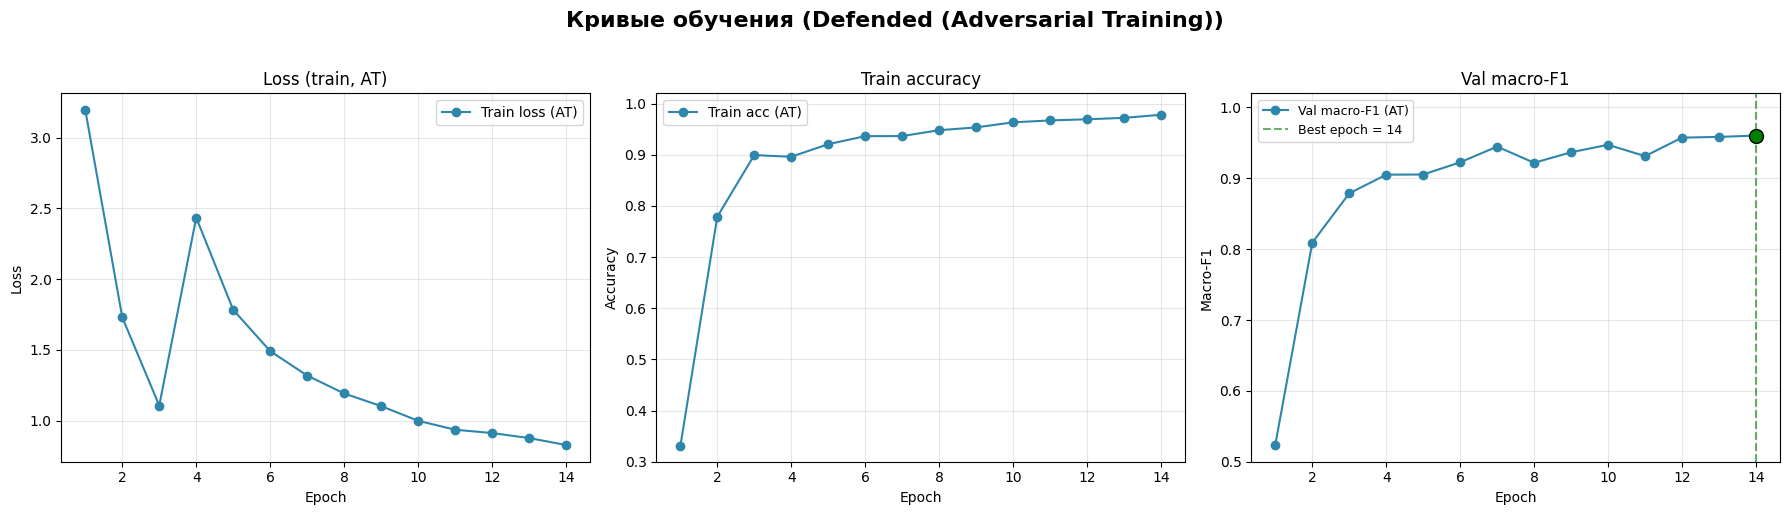

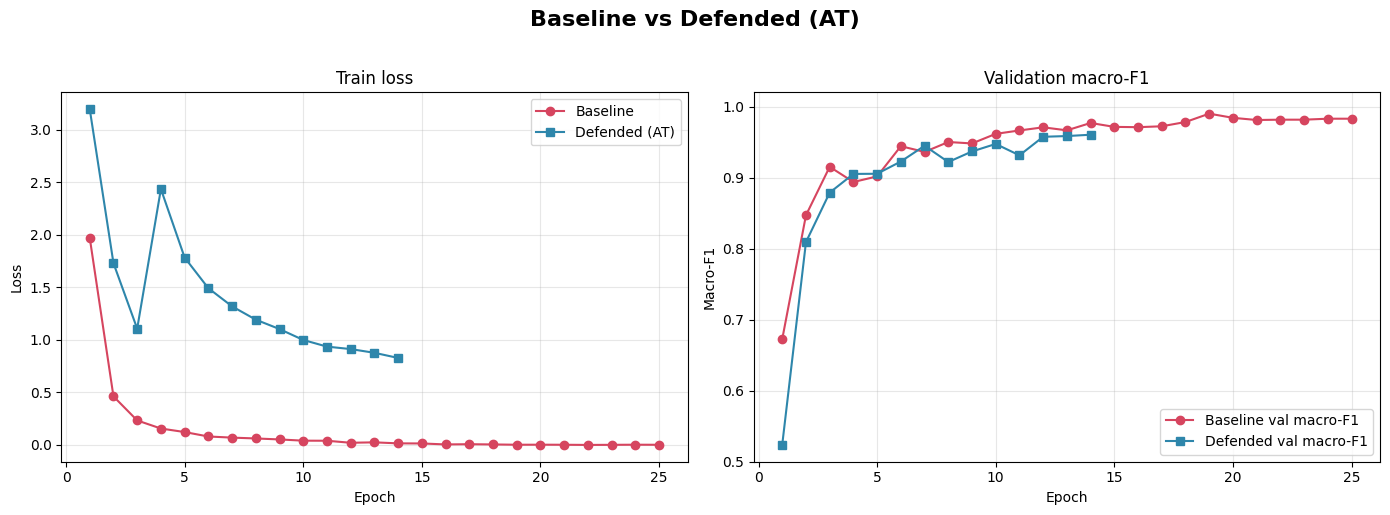


Итог:
Модель           Clean acc    Bal acc   Macro-F1   FGSM ASR    PGD ASR
------------------------------------------------------------------------
Baseline            0.9769     0.9801     0.9744     0.5319     0.9976
Defended (AT)       0.9261     0.9268     0.9077     0.1696     0.6808
------------------------------------------------------------------------
delta(AT - Baseline)    -0.0508    -0.0533    -0.0668    -0.3623    -0.3168


In [ ]:
# кривые обучения defended(AT)
import matplotlib.pyplot as plt
import numpy as np

h = at_history
epochs = np.arange(1, len(h["loss"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Кривые обучения (Defended (Adversarial Training))", fontsize=16, fontweight="bold", y=1.02)

# loss
axes[0].plot(epochs, h["loss"], "o-", color="#2E86AB", label="Train loss (AT)")
axes[0].set_title("Loss (train, AT)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(alpha=0.3)
axes[0].legend()

# train acc
axes[1].plot(epochs, h["train_acc"], "o-", color="#2E86AB", label="Train acc (AT)")
axes[1].set_title("Train accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0.3, 1.02)
axes[1].grid(alpha=0.3)
axes[1].legend()

# val F1+best
axes[2].plot(epochs, h["val_f1"], "o-", color="#2E86AB", label="Val macro-F1 (AT)")
best_ep = int(np.argmax(h["val_f1"])) + 1
best_f1_val = max(h["val_f1"])
axes[2].axvline(best_ep, ls="--", color="green", alpha=0.6, label=f"Best epoch = {best_ep}")
axes[2].scatter([best_ep], [h["val_f1"][best_ep - 1]], color="green", s=100, zorder=5, edgecolor="k")
axes[2].set_title("Val macro-F1")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Macro-F1")
axes[2].set_ylim(0.5, 1.02)
axes[2].grid(alpha=0.3)
axes[2].legend(fontsize=9)

plt.tight_layout()
plt.show()


# сравнение baseline и defended
if "baseline_history" in globals():
    hb = baseline_history
    hd = at_history

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle("Baseline vs Defended (AT)", fontsize=16, fontweight="bold", y=1.02)

    # loss
    axes[0].plot(range(1, len(hb["loss"])+1), hb["loss"], "o-", color="#D6455F", label="Baseline")
    axes[0].plot(range(1, len(hd["loss"])+1), hd["loss"], "s-", color="#2E86AB", label="Defended (AT)")
    axes[0].set_title("Train loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].grid(alpha=0.3)
    axes[0].legend()

    # val F1
    axes[1].plot(range(1, len(hb["val_macro_f1"])+1), hb["val_macro_f1"], "o-", color="#D6455F", label="Baseline val macro-F1")
    axes[1].plot(range(1, len(hd["val_f1"])+1), hd["val_f1"], "s-", color="#2E86AB", label="Defended val macro-F1")
    axes[1].set_title("Validation macro-F1")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Macro-F1")
    axes[1].set_ylim(0.5, 1.02)
    axes[1].grid(alpha=0.3)
    axes[1].legend()

    plt.tight_layout()
    plt.show()

    print("\nИтог:")
    print(f"{'Модель':<15} {'Clean acc':>10} {'Bal acc':>10} {'Macro-F1':>10} {'FGSM ASR':>10} {'PGD ASR':>10}")
    print("-" * 72)
    print(f"{'Baseline':<15} {tm['acc']:>10.4f} {tm['bal_acc']:>10.4f} {tm['macro_f1']:>10.4f} "f"{asr_fgsm_base:>10.4f} {asr_pgd_base:>10.4f}")
    print(f"{'Defended (AT)':<15} {_tm_def['acc']:>10.4f} {_tm_def['bal_acc']:>10.4f} "f"{_tm_def['macro_f1']:>10.4f} {asr_fgsm_def:>10.4f} {asr_pgd_def:>10.4f}")

    # разница
    print("-" * 72)
    print(f"{'delta(AT - Baseline)':<15} {_tm_def['acc']-tm['acc']:>+10.4f} "
          f"{_tm_def['bal_acc']-tm['bal_acc']:>+10.4f} "
          f"{_tm_def['macro_f1']-tm['macro_f1']:>+10.4f} "
          f"{asr_fgsm_def-asr_fgsm_base:>+10.4f} {asr_pgd_def-asr_pgd_base:>+10.4f}")

In [ ]:
final_path = os.path.join(CHECKPOINT_DIR, "defended_final.pth")
torch.save({
    'model_state_dict': defended_model.state_dict(),
    'best_f1_from_history': max(at_history["val_f1"]),
    'history': at_history,
    'config': {
        'epsilon': 0.03, 'alpha': 0.01, 'num_iter': 10,
        'adv_weight': 0.5, 'epochs_total': 15,
        'arch': 'resnet18', 'num_classes': NUM_CLASSES,
    },
}, final_path)
print(f"Финальная defended-модель сохранена: {final_path}")
print(f"Размер файла: {os.path.getsize(final_path) / 1e6:.1f} MB")

Финальная defended-модель сохранена: /content/drive/MyDrive/traffic_signs_checkpoints/defended_final.pth
Размер файла: 44.9 MB


eps = 0.01
FGSM baseline=0.277 defended=0.090
PGD baseline=0.804 defended=0.150
eps = 0.03
FGSM baseline=0.532 defended=0.170
PGD baseline=0.998 defended=0.663
eps = 0.05
FGSM baseline=0.574 defended=0.202
PGD baseline=1.000 defended=0.940


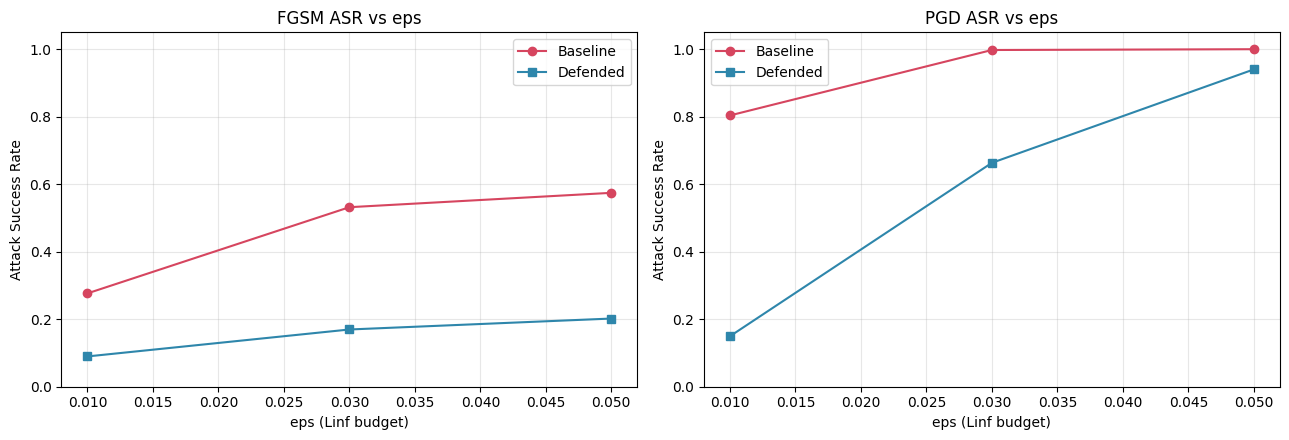

In [ ]:
# ASR при разных eps (FGSM и PGD)
epsilons = [0.01, 0.03, 0.05]
results = {
    "FGSM": {"baseline": [], "defended": []},
    "PGD":  {"baseline": [], "defended": []},
}

for eps in epsilons:
    print(f"eps = {eps}")

    # FGSM
    _, asr_b_f = evaluate_asr(baseline_model, val_loader, fgsm_attack, eps, criterion=criterion)
    _, asr_d_f = evaluate_asr(defended_model, val_loader, fgsm_attack, eps, criterion=criterion)
    results["FGSM"]["baseline"].append(asr_b_f)
    results["FGSM"]["defended"].append(asr_d_f)

    # PGD (alpha = eps/4, num_iter=10)
    _, asr_b_p = evaluate_asr(baseline_model, val_loader, pgd_attack, eps,
                              alpha=eps/4, num_iter=10, criterion=criterion)
    _, asr_d_p = evaluate_asr(defended_model, val_loader, pgd_attack, eps,
                              alpha=eps/4, num_iter=10, criterion=criterion)
    results["PGD"]["baseline"].append(asr_b_p)
    results["PGD"]["defended"].append(asr_d_p)

    print(f"FGSM baseline={asr_b_f:.3f} defended={asr_d_f:.3f}")
    print(f"PGD baseline={asr_b_p:.3f} defended={asr_d_p:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, atk in zip(axes, ["FGSM", "PGD"]):
    ax.plot(epsilons, results[atk]["baseline"], "o-", label="Baseline", color="#D6455F")
    ax.plot(epsilons, results[atk]["defended"], "s-", label="Defended", color="#2E86AB")
    ax.set_title(f"{atk} ASR vs eps")
    ax.set_xlabel("eps (Linf budget)")
    ax.set_ylabel("Attack Success Rate")
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout(); plt.show()

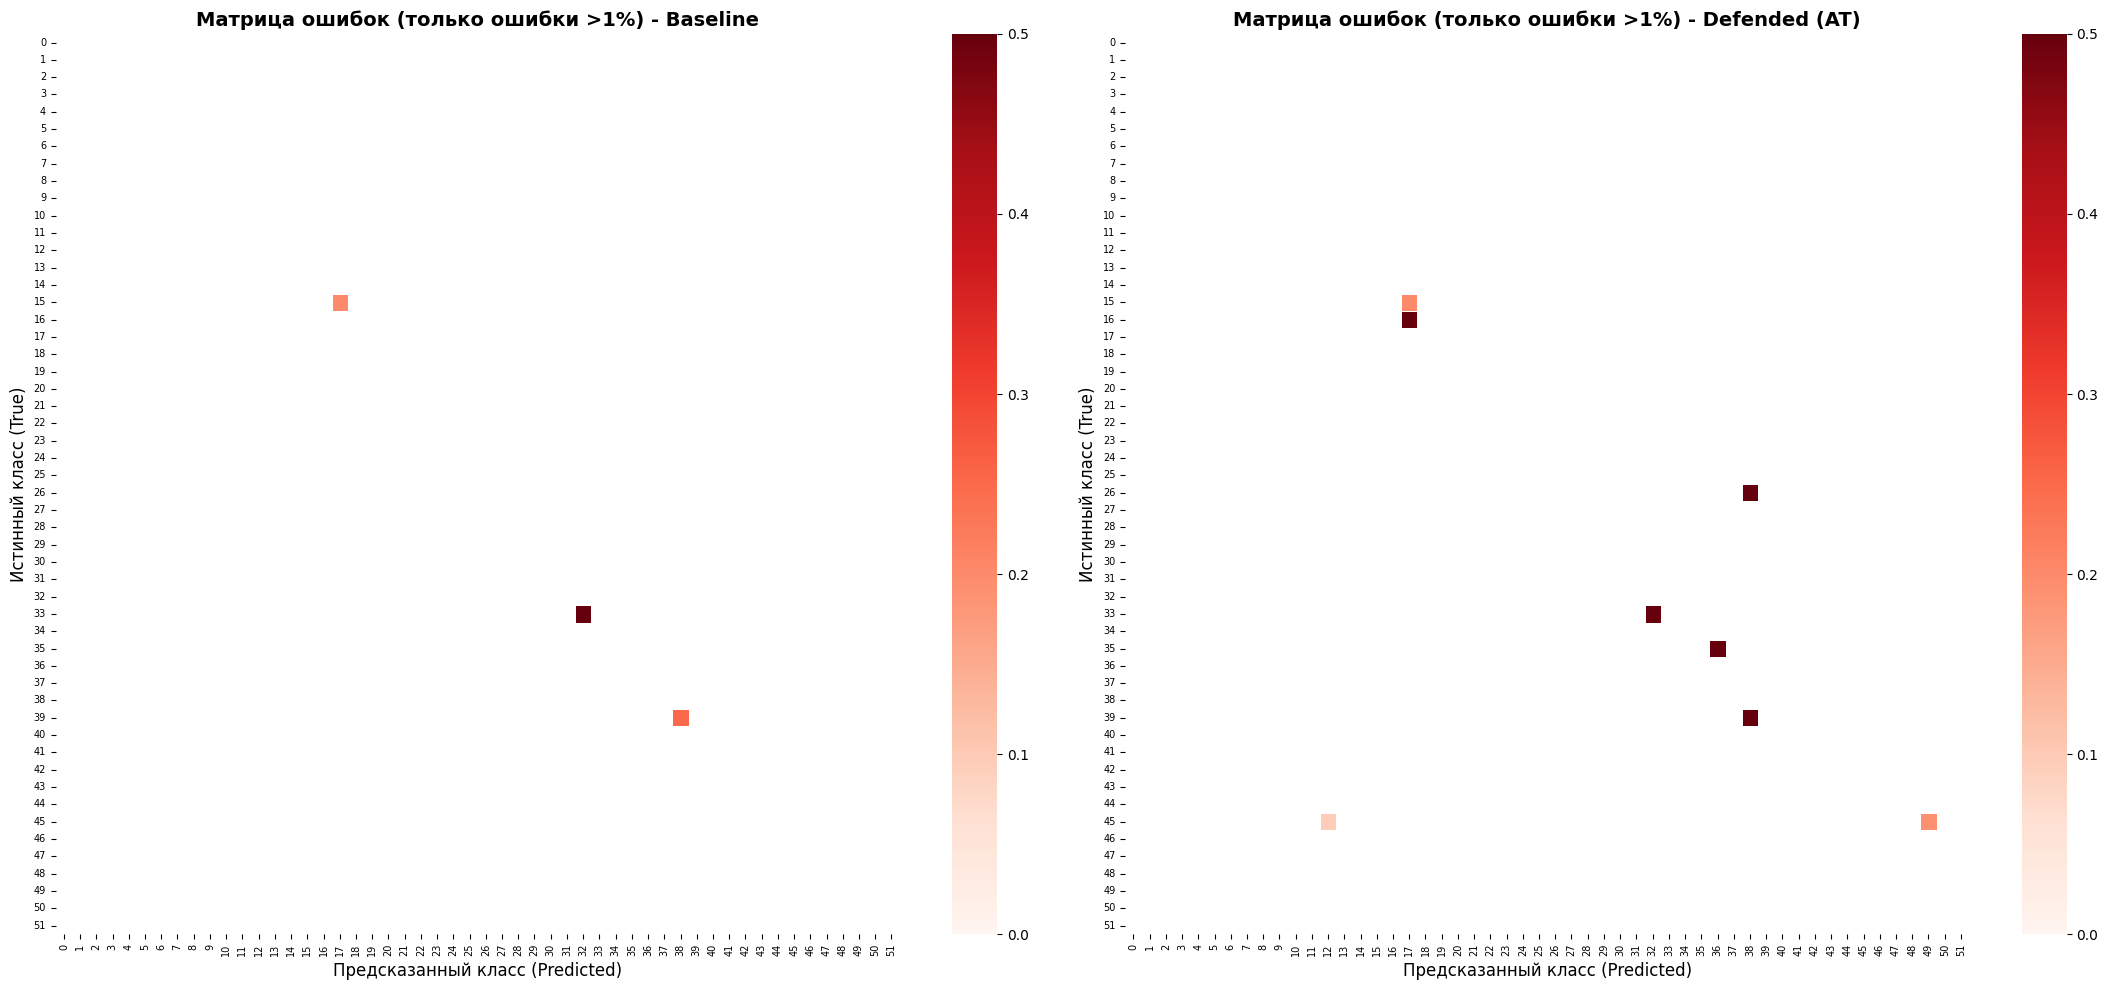

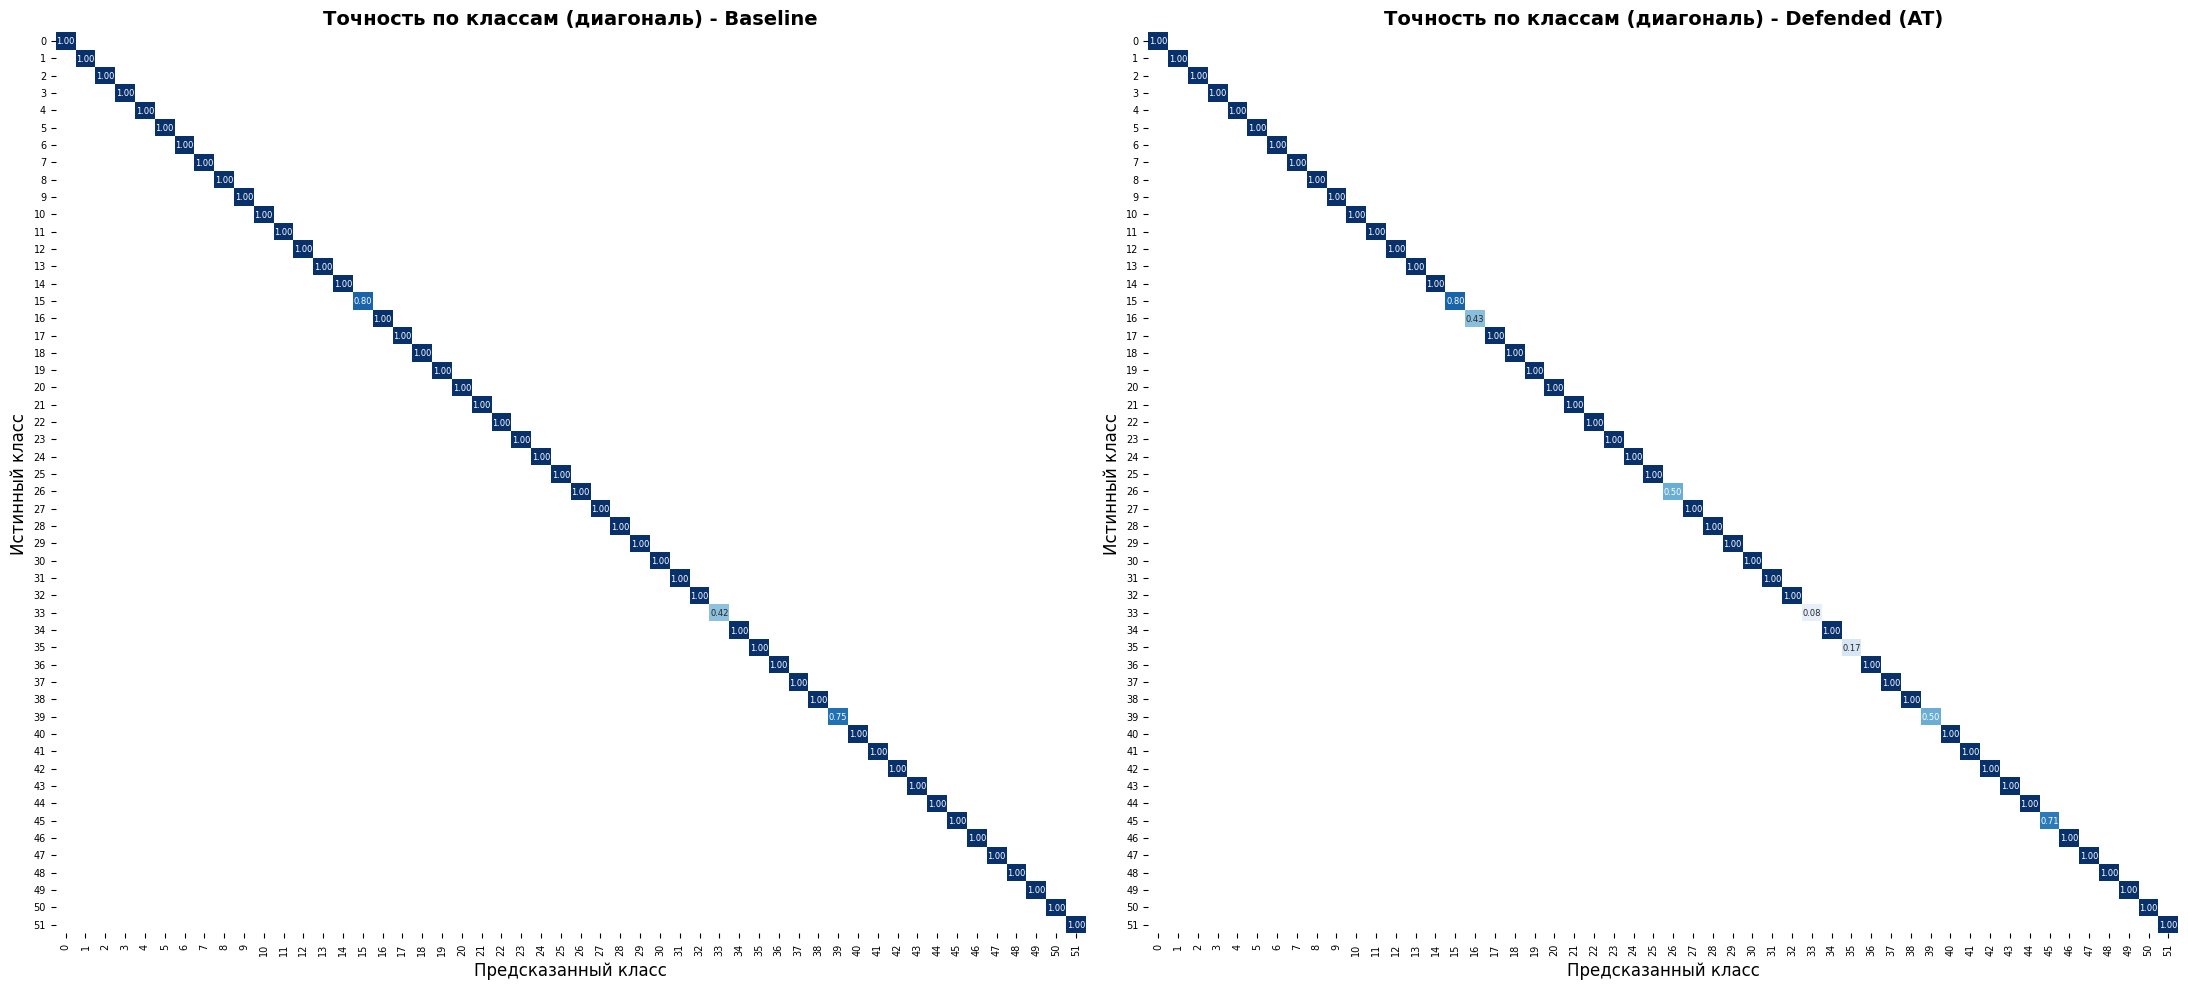


Топ-10 путаниц: baseline (true на pred)
  7      39  на  38    
  2      44  на  43    
  1      22  на  24    

Топ-10 путаниц: defended (true на pred)
 11      39  на  38    
  5      40  на  41    
  4       5  на  7     
  4      44  на  43    
  4      23  на  24    
  2       5  на  2     
  1      32  на  43    
  1      22  на  24    


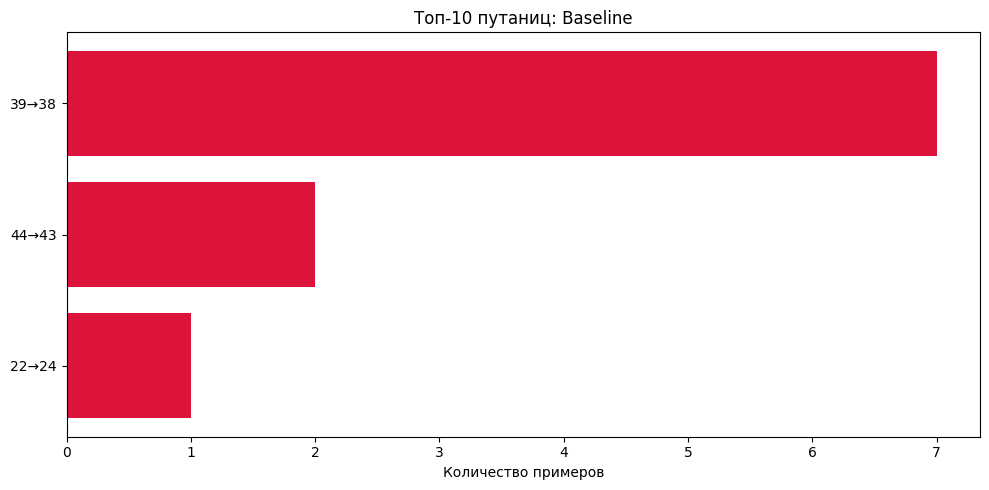

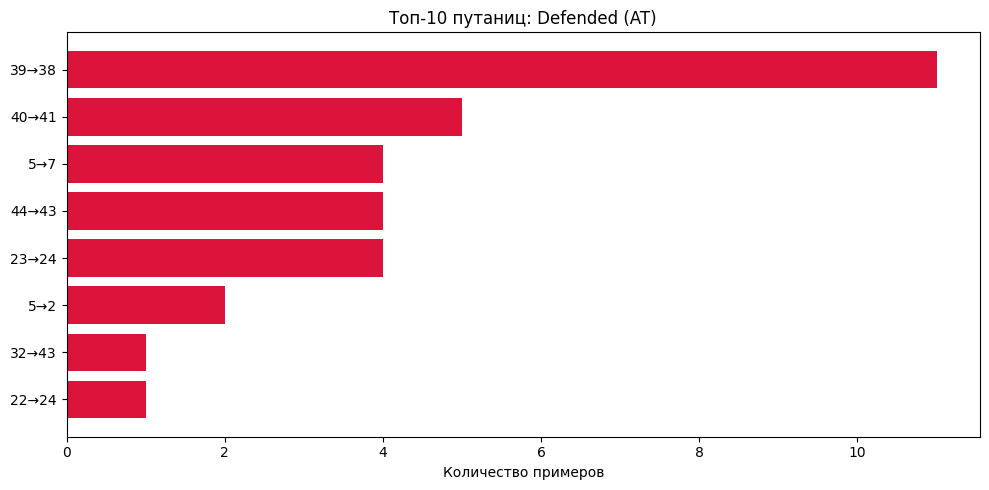

In [ ]:
# матрица ошибок
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np
import matplotlib.pyplot as plt

def get_cm(model, loader):
    model.eval()
    ys, ps = [], []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(DEVICE)
            ps.extend(model(x).argmax(1).cpu().numpy())
            ys.extend(y.numpy())
    return np.array(ys), np.array(ps)

y_true_b, y_pred_b = get_cm(baseline_model, val_loader)
y_true_d, y_pred_d = get_cm(defended_model, val_loader)

class_names = full_train_dataset.classes
cm_b = confusion_matrix(y_true_b, y_pred_b, labels=list(range(NUM_CLASSES)))
cm_d = confusion_matrix(y_true_d, y_pred_d, labels=list(range(NUM_CLASSES)))

fig, axes = plt.subplots(1, 2, figsize=(22, 10))
for ax, cm, title in zip(axes, [cm_b, cm_d], ["Baseline", "Defended (AT)"]):
    cm_norm = cm.astype(float) / np.maximum(cm.sum(axis=1, keepdims=True), 1)

    mask_diag = np.eye(NUM_CLASSES, dtype=bool)
    mask = mask_diag | (cm_norm < 0.01)

    sns.heatmap(cm_norm, ax=ax, cmap="Reds", cbar=True,
                xticklabels=range(NUM_CLASSES),
                yticklabels=range(NUM_CLASSES),
                vmin=0, vmax=0.5,
                mask=mask,
                linewidths=.5)

    ax.set_title(f"Матрица ошибок (только ошибки >1%) - {title}", fontsize=14, fontweight='bold')
    ax.set_xlabel("Предсказанный класс (Predicted)", fontsize=12)
    ax.set_ylabel("Истинный класс (True)", fontsize=12)

    ax.tick_params(axis='x', rotation=90, labelsize=7)
    ax.tick_params(axis='y', rotation=0, labelsize=7)

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(22, 10))
for ax, cm, title in zip(axes, [cm_b, cm_d], ["Baseline", "Defended (AT)"]):
    cm_norm = cm.astype(float) / np.maximum(cm.sum(axis=1, keepdims=True), 1)

    mask_off_diag = ~np.eye(NUM_CLASSES, dtype=bool)

    sns.heatmap(cm_norm, ax=ax, cmap="Blues", cbar=False,
                xticklabels=range(NUM_CLASSES),
                yticklabels=range(NUM_CLASSES),
                vmin=0, vmax=1,
                mask=mask_off_diag,
                annot=True, fmt=".2f",
                annot_kws={"size": 6})

    ax.set_title(f"Точность по классам (диагональ) - {title}", fontsize=14, fontweight='bold')
    ax.set_xlabel("Предсказанный класс", fontsize=12)
    ax.set_ylabel("Истинный класс", fontsize=12)
    ax.tick_params(axis='x', rotation=90, labelsize=7)
    ax.tick_params(axis='y', rotation=0, labelsize=7)

plt.tight_layout()
plt.show()

# топ-10 самых путаемых пар
def top_confusions(cm, k=10):
    pairs = []
    n = cm.shape[0]
    for i in range(n):
        for j in range(n):
            if i != j and cm[i, j] > 0:
                pairs.append((cm[i, j], i, j))
    pairs.sort(reverse=True)
    return pairs[:k]

print("\nТоп-10 путаниц: baseline (true на pred)")
for cnt, i, j in top_confusions(cm_b, 10):
    print(f"{cnt:3d}  {class_names[i]:>6}  на  {class_names[j]:<6}")

print("\nТоп-10 путаниц: defended (true на pred)")
for cnt, i, j in top_confusions(cm_d, 10):
    print(f"{cnt:3d}  {class_names[i]:>6}  на  {class_names[j]:<6}")

def plot_top_confusions(cm, class_names, title, top_k=10):
    pairs = top_confusions(cm, top_k)
    if not pairs:
        print(f"[{title}] нет путаниц"); return
    counts = [p[0] for p in pairs]
    labels = [f"{class_names[p[1]]}→{class_names[p[2]]}" for p in pairs]
    plt.figure(figsize=(10, 5))
    plt.barh(range(len(labels))[::-1], counts, color="crimson")
    plt.yticks(range(len(labels))[::-1], labels, fontsize=10)
    plt.xlabel("Количество примеров")
    plt.title(f"Топ-{top_k} путаниц: {title}")
    plt.tight_layout(); plt.show()

plot_top_confusions(cm_b, class_names, "Baseline", 10)
plot_top_confusions(cm_d, class_names, "Defended (AT)", 10)

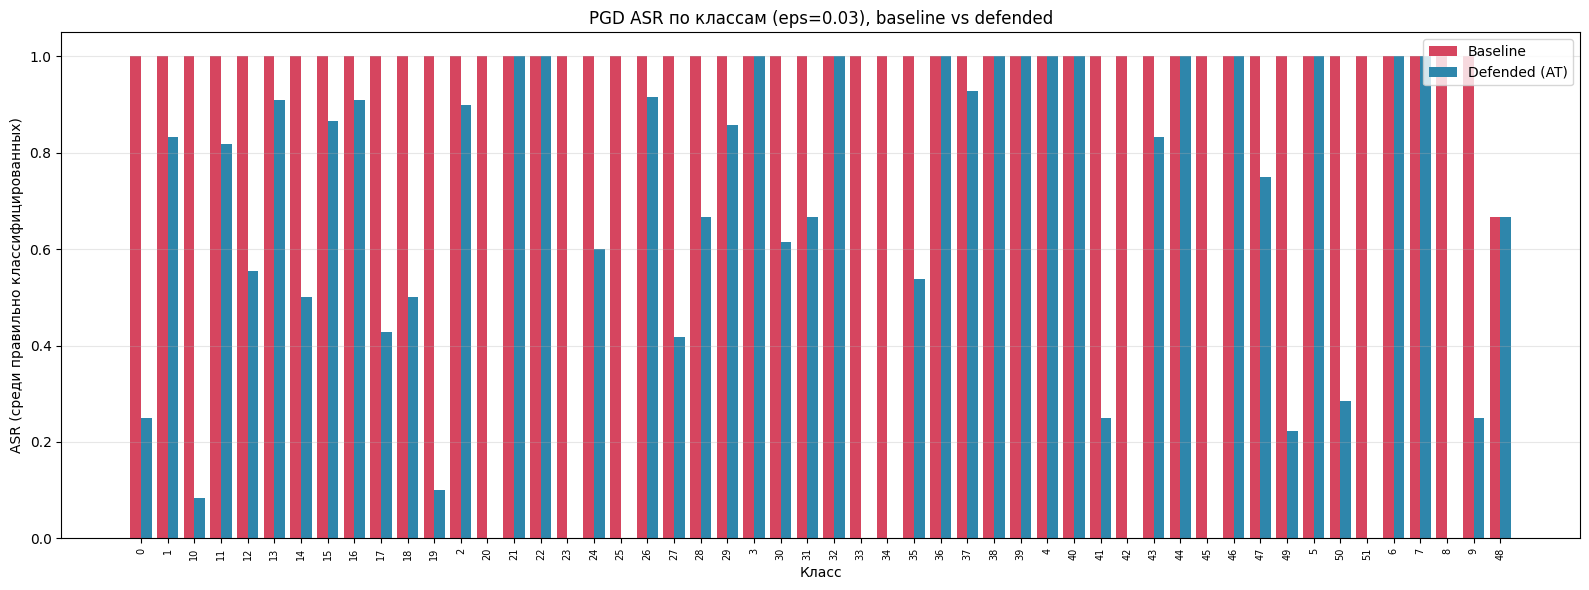

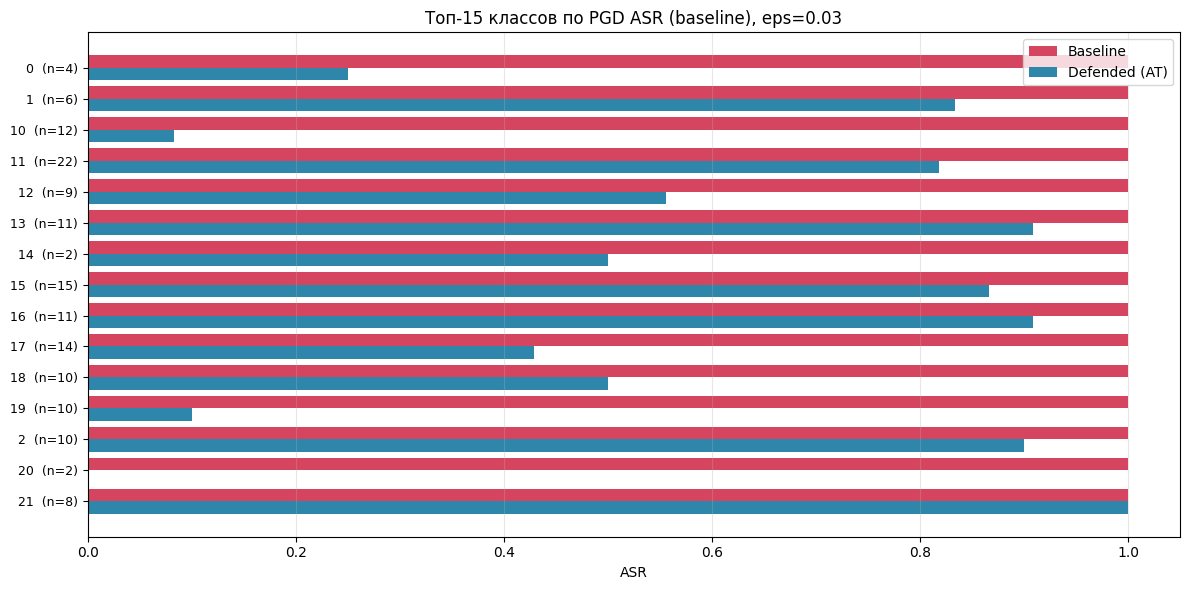

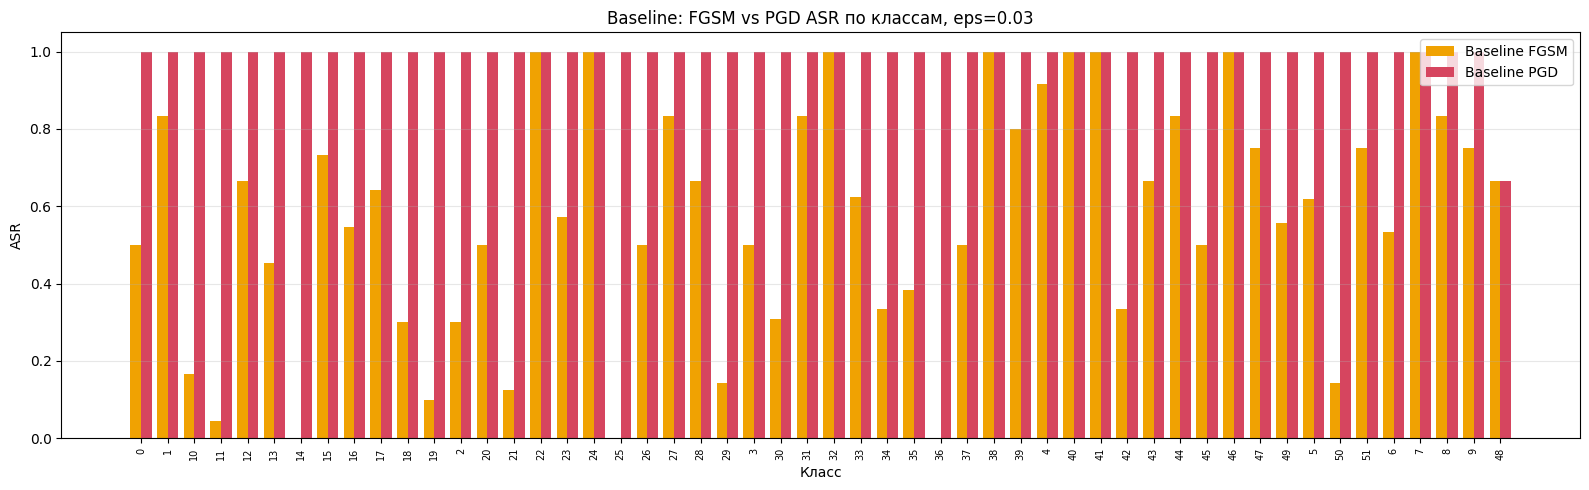

,class,n_correct_baseline,ASR_baseline_PGD,ASR_defended_PGD,ASR_baseline_FGSM,ASR_defended_FGSM
0,0,4,1.0,0.250000,0.500000,0.000000
1,1,6,1.0,0.833333,0.833333,0.333333
2,10,12,1.0,0.083333,0.166667,0.000000
3,11,22,1.0,0.818182,0.045455,0.409091
4,12,9,1.0,0.555556,0.666667,0.000000
5,13,11,1.0,0.909091,0.454545,0.000000
6,14,2,1.0,0.500000,0.000000,0.000000
7,15,15,1.0,0.866667,0.733333,0.133333
8,16,11,1.0,0.909091,0.545455,0.363636
9,17,14,1.0,0.428571,0.642857,0.000000



PGD eps=0.03 - ASR по классам (среднее по классам):
Baseline: mean ASR = 0.9936, классов с ASR>=0.99: 51/52, классов с ASR<=0.01: 0
Defended: mean ASR = 0.5984, классов с ASR>=0.99: 14/52, классов с ASR<=0.01: 9


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict

def per_class_asr(model, loader, attack_fn, epsilon, num_classes, **attack_kwargs):
    model.eval()
    correct = defaultdict(int)
    total = defaultdict(int)
    attacked = defaultdict(int)
    success = defaultdict(int)

    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.no_grad():
            pred = model(x).argmax(1)
        mask = pred == y

        # считаем total и correct по классам
        for cls in y.cpu().numpy():
            total[int(cls)] += 1
        for cls in y[mask].cpu().numpy():
            correct[int(cls)] += 1

        if mask.any():
            x_ok, y_ok = x[mask], y[mask]
            x_adv = attack_fn(model, x_ok, y_ok, epsilon, **attack_kwargs)
            with torch.no_grad():
                pred_adv = model(x_adv).argmax(1)
            succ_mask = (pred_adv != y_ok)
            for cls in y_ok[succ_mask].cpu().numpy():
                success[int(cls)] += 1
            for cls in y_ok.cpu().numpy():
                attacked[int(cls)] += 1

    asr = {}
    for c in range(num_classes):
        asr[c] = (success[c] / attacked[c]) if attacked[c] > 0 else np.nan

    return asr, dict(correct), dict(total)


# считаем ASR по классам для PGD
EPS = 0.03
asr_b_pgd, corr_b, tot_b = per_class_asr(baseline_model, val_loader, pgd_attack, EPS, NUM_CLASSES, alpha=EPS/4, num_iter=10, criterion=criterion,)
asr_d_pgd, corr_d, tot_d = per_class_asr(defended_model, val_loader, pgd_attack, EPS, NUM_CLASSES, alpha=EPS/4, num_iter=10, criterion=criterion,)

asr_b_fgsm, _, _ = per_class_asr(baseline_model, val_loader, fgsm_attack, EPS, NUM_CLASSES, criterion=criterion,)
asr_d_fgsm, _, _ = per_class_asr(defended_model, val_loader, fgsm_attack, EPS, NUM_CLASSES, criterion=criterion,)

# сортируем классы по ASR baseline (PGD)
valid_classes = [c for c in range(NUM_CLASSES) if not np.isnan(asr_b_pgd[c])]
sorted_classes = sorted(valid_classes, key=lambda c: asr_b_pgd[c], reverse=True)

labels = [str(class_names[c]) for c in sorted_classes]
vals_b = [asr_b_pgd[c] for c in sorted_classes]
vals_d = [asr_d_pgd[c] for c in sorted_classes]
n_ok_b = [corr_b.get(c, 0) for c in sorted_classes]

# PGD ASR по классам
fig, ax = plt.subplots(figsize=(16, 6))
x = np.arange(len(sorted_classes))
w = 0.4
ax.bar(x - w/2, vals_b, w, label="Baseline", color="#D6455F")
ax.bar(x + w/2, vals_d, w, label="Defended (AT)", color="#2E86AB")
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=90, fontsize=7)
ax.set_ylabel("ASR (среди правильно классифицированных)")
ax.set_xlabel("Класс")
ax.set_title(f"PGD ASR по классам (eps={EPS}), baseline vs defended")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# топ-15 классов которые ломаются чаще
top_k = 15
top_classes = sorted_classes[:top_k]
top_labels = [str(class_names[c]) for c in top_classes]
top_vals_b = [asr_b_pgd[c] for c in top_classes]
top_vals_d = [asr_d_pgd[c] for c in top_classes]
top_n = [corr_b.get(c, 0) for c in top_classes]

fig, ax = plt.subplots(figsize=(12, 6))
y = np.arange(len(top_classes))[::-1]
ax.barh(y + 0.2, top_vals_b, 0.4, label="Baseline", color="#D6455F")
ax.barh(y - 0.2, top_vals_d, 0.4, label="Defended (AT)", color="#2E86AB")
ax.set_yticks(y)
ax.set_yticklabels([f"{lab}  (n={n})" for lab, n in zip(top_labels, top_n)], fontsize=9)
ax.set_xlabel("ASR")
ax.set_xlim(0, 1.05)
ax.set_title(f"Топ-{top_k} классов по PGD ASR (baseline), eps={EPS}")
ax.grid(axis="x", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# FGSM vs PGD ASR по классам (baseline)
fig, ax = plt.subplots(figsize=(16, 5))
ax.bar(x - w/2, [asr_b_fgsm[c] for c in sorted_classes], w,
       label="Baseline FGSM", color="#F0A202")
ax.bar(x + w/2, [asr_b_pgd[c] for c in sorted_classes], w,
       label="Baseline PGD", color="#D6455F")
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=90, fontsize=7)
ax.set_ylabel("ASR")
ax.set_xlabel("Класс")
ax.set_title(f"Baseline: FGSM vs PGD ASR по классам, eps={EPS}")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# топ-15 самых уязвимых классов (baseline PGD)
import pandas as pd
rows = []
for c in top_classes:
    rows.append({
        "class": class_names[c],
        "n_correct_baseline": corr_b.get(c, 0),
        "ASR_baseline_PGD": asr_b_pgd[c],
        "ASR_defended_PGD": asr_d_pgd[c],
        "ASR_baseline_FGSM": asr_b_fgsm[c],
        "ASR_defended_FGSM": asr_d_fgsm[c],
    })
display(pd.DataFrame(rows))

mean_asr_b = np.nanmean([asr_b_pgd[c] for c in valid_classes])
mean_asr_d = np.nanmean([asr_d_pgd[c] for c in valid_classes])
n_fully_broken_b = sum(1 for c in valid_classes if asr_b_pgd[c] >= 0.99)
n_fully_broken_d = sum(1 for c in valid_classes if asr_d_pgd[c] >= 0.99)
n_fully_robust_b = sum(1 for c in valid_classes if asr_b_pgd[c] <= 0.01)
n_fully_robust_d = sum(1 for c in valid_classes if asr_d_pgd[c] <= 0.01)

print(f"\nPGD eps={EPS} - ASR по классам (среднее по классам):")
print(f"Baseline: mean ASR = {mean_asr_b:.4f}, "f"классов с ASR>=0.99: {n_fully_broken_b}/{len(valid_classes)}, "f"классов с ASR<=0.01: {n_fully_robust_b}")
print(f"Defended: mean ASR = {mean_asr_d:.4f}, "f"классов с ASR>=0.99: {n_fully_broken_d}/{len(valid_classes)}, "f"классов с ASR<=0.01: {n_fully_robust_d}")

,Model,Clean F1,FGSM ASR,PGD ASR
0,Baseline,0.974447,0.531915,0.997636
1,Defended (AT),0.907695,0.169576,0.680798


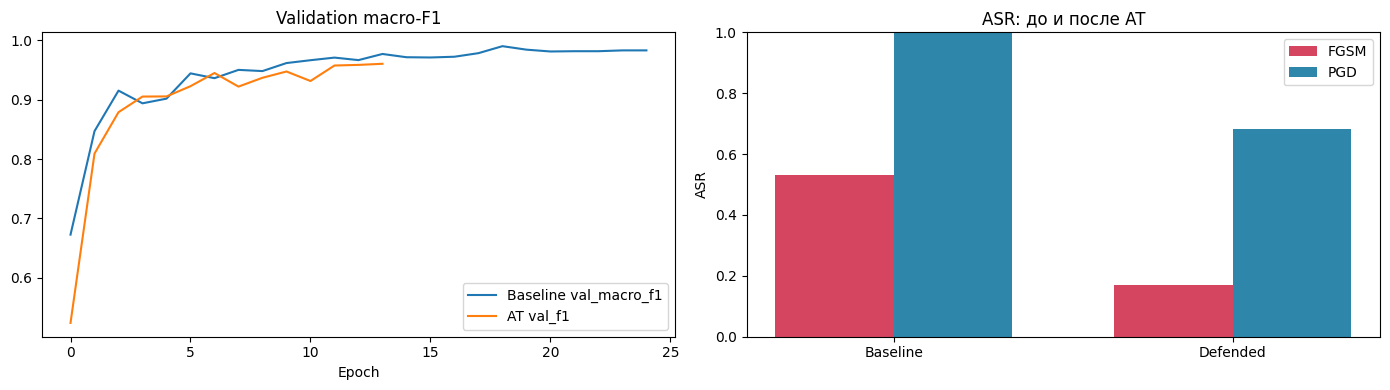

In [ ]:
baseline_f1 = tm["macro_f1"] if isinstance(tm, dict) else float(tm)

summary = pd.DataFrame([
    {"Model": "Baseline", "Clean F1": baseline_f1, "FGSM ASR": asr_fgsm_base, "PGD ASR": asr_pgd_base},
    {"Model": "Defended (AT)", "Clean F1": defended_f1, "FGSM ASR": asr_fgsm_def,  "PGD ASR": asr_pgd_def},
])
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(baseline_history["val_macro_f1"], label="Baseline val_macro_f1")
axes[0].plot(at_history["val_f1"],             label="AT val_f1")
axes[0].set_title("Validation macro-F1")
axes[0].set_xlabel("Epoch"); axes[0].legend()

x = np.arange(2); w = 0.35
axes[1].bar(x - w/2, [asr_fgsm_base, asr_fgsm_def], w, label="FGSM", color="#D6455F")
axes[1].bar(x + w/2, [asr_pgd_base,  asr_pgd_def],  w, label="PGD",  color="#2E86AB")
axes[1].set_xticks(x); axes[1].set_xticklabels(["Baseline", "Defended"])
axes[1].set_ylabel("ASR"); axes[1].set_ylim(0, 1)
axes[1].set_title("ASR: до и после AT"); axes[1].legend()
plt.tight_layout(); plt.show()

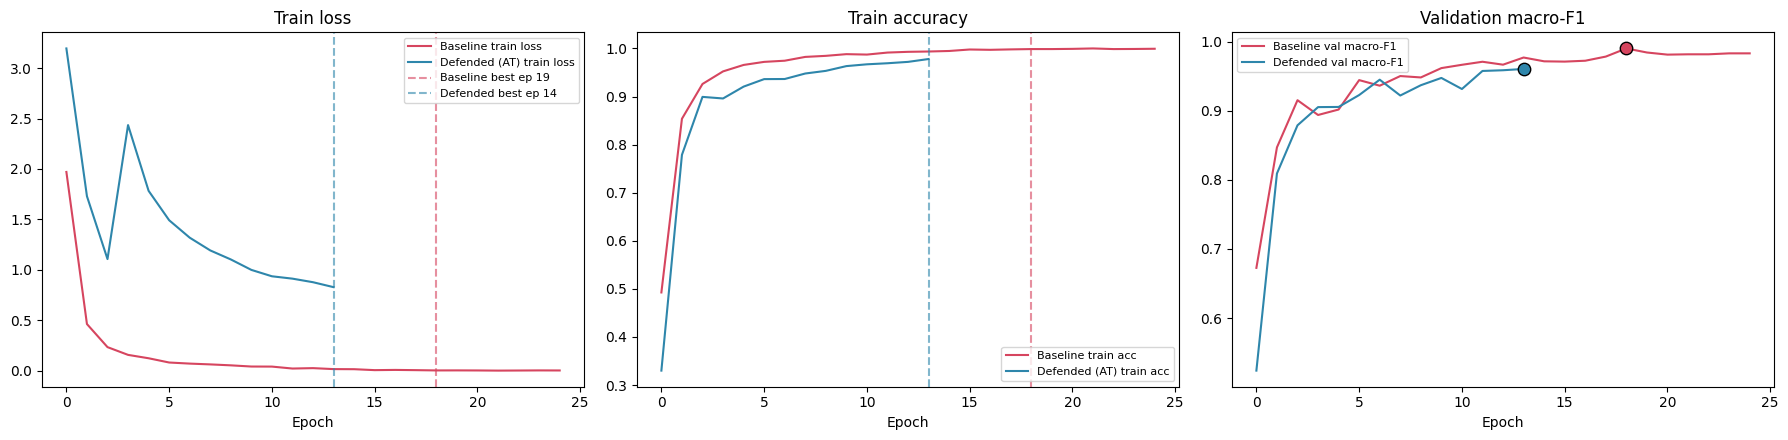

Baseline: best val_macro_f1 = 0.9900 (epoch 19)
Defended: best val_f1 = 0.9603 (epoch 14)


In [ ]:
# керивые обучения
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# loss
axes[0].plot(baseline_history["loss"], label="Baseline train loss", color="#D6455F")
axes[0].plot(at_history["loss"], label="Defended (AT) train loss", color="#2E86AB")
best_b = int(np.argmax(baseline_history["val_macro_f1"]))
best_d = int(np.argmax(at_history["val_f1"]))
axes[0].axvline(best_b, ls="--", color="#D6455F", alpha=0.6, label=f"Baseline best ep {best_b+1}")
axes[0].axvline(best_d, ls="--", color="#2E86AB", alpha=0.6, label=f"Defended best ep {best_d+1}")
axes[0].set_title("Train loss")
axes[0].set_xlabel("Epoch"); axes[0].legend(fontsize=8)

# train acc
axes[1].plot(baseline_history["train_acc"], label="Baseline train acc", color="#D6455F")
axes[1].plot(at_history["train_acc"], label="Defended (AT) train acc", color="#2E86AB")
axes[1].axvline(best_b, ls="--", color="#D6455F", alpha=0.6)
axes[1].axvline(best_d, ls="--", color="#2E86AB", alpha=0.6)
axes[1].set_title("Train accuracy")
axes[1].set_xlabel("Epoch"); axes[1].legend(fontsize=8)

# val macro-F1
axes[2].plot(baseline_history["val_macro_f1"], label="Baseline val macro-F1", color="#D6455F")
axes[2].plot(at_history["val_f1"], label="Defended val macro-F1", color="#2E86AB")
axes[2].scatter([best_b], [baseline_history["val_macro_f1"][best_b]], color="#D6455F", s=80, zorder=5, edgecolor="k")
axes[2].scatter([best_d], [at_history["val_f1"][best_d]], color="#2E86AB", s=80, zorder=5, edgecolor="k")
axes[2].set_title("Validation macro-F1")
axes[2].set_xlabel("Epoch"); axes[2].legend(fontsize=8)

plt.tight_layout(); plt.show()

print(f"Baseline: best val_macro_f1 = {baseline_history['val_macro_f1'][best_b]:.4f} (epoch {best_b+1})")
print(f"Defended: best val_f1 = {at_history['val_f1'][best_d]:.4f} (epoch {best_d+1})")

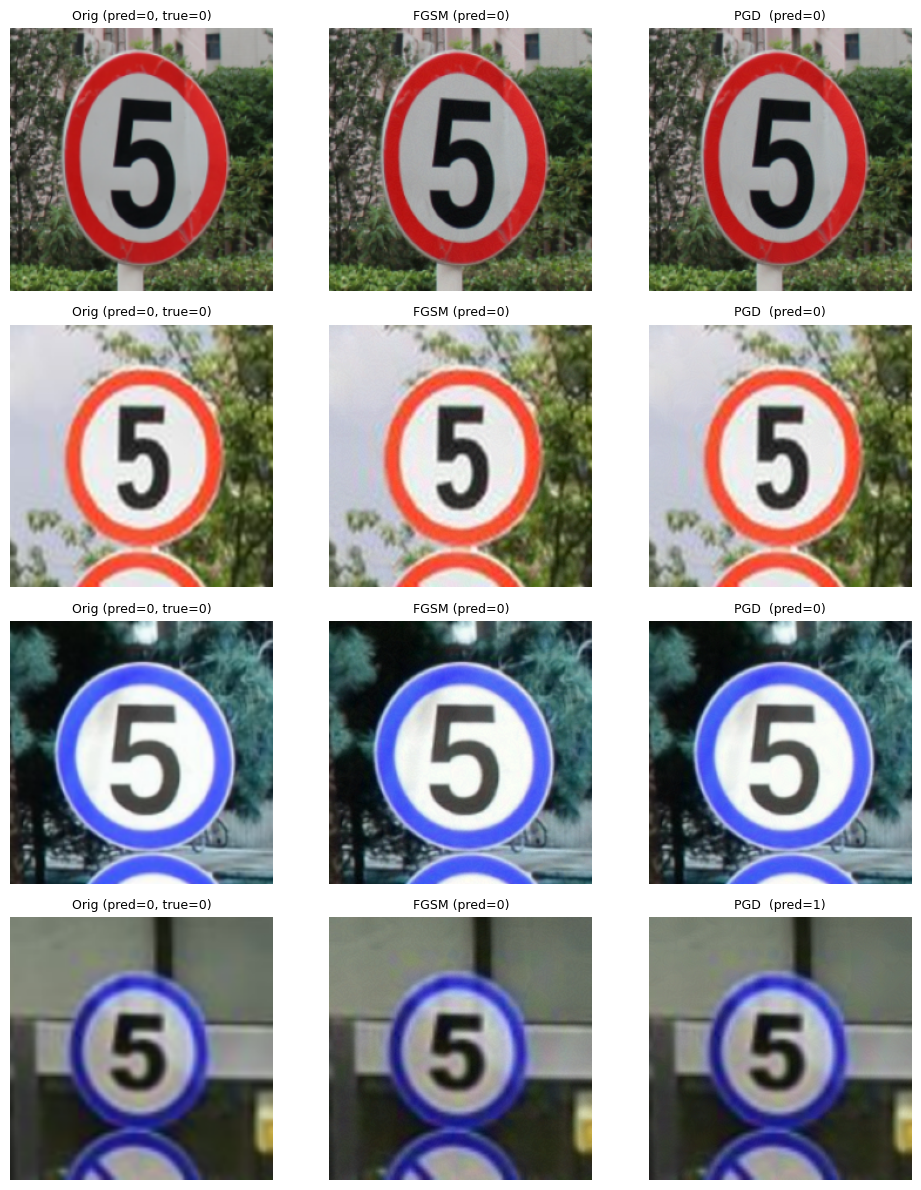

In [ ]:
def visualize_attack(model, loader, epsilon=0.03, n=4):
    model.eval()
    imgs, labs = [], []
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.no_grad():
            pred = model(x).argmax(1)
        m = pred == y
        if m.any():
            imgs.append(x[m]); labs.append(y[m])
        if sum(t.size(0) for t in imgs) >= n:
            break
    x = torch.cat(imgs)[:n]; y = torch.cat(labs)[:n]

    def denorm(t):
        mean = torch.tensor([0.485, 0.456, 0.406], device=t.device).view(1,3,1,1)
        std  = torch.tensor([0.229, 0.224, 0.225], device=t.device).view(1,3,1,1)
        return (t * std + mean).clamp(0, 1)

    x_fgsm = fgsm_attack(model, x, y, epsilon, criterion)
    x_pgd  = pgd_attack(model, x, y, epsilon, alpha=epsilon/4, num_iter=10, criterion=criterion)

    with torch.no_grad():
        p0 = model(x).argmax(1); p1 = model(x_fgsm).argmax(1); p2 = model(x_pgd).argmax(1)

    fig, axes = plt.subplots(n, 3, figsize=(10, 3*n))
    if n == 1: axes = [axes]
    for i in range(n):
        for j, (img, title) in enumerate([
            (x[i], f"Orig (pred={p0[i].item()}, true={y[i].item()})"),
            (x_fgsm[i], f"FGSM (pred={p1[i].item()})"),
            (x_pgd[i], f"PGD  (pred={p2[i].item()})"),
        ]):
            axes[i, j].imshow(denorm(img.unsqueeze(0))[0].permute(1,2,0).cpu().numpy())
            axes[i, j].set_title(title, fontsize=9); axes[i, j].axis("off")
    plt.tight_layout(); plt.show()

visualize_attack(defended_model, val_loader, epsilon=0.03, n=4)

In [ ]:
import torch, gc
import numpy as np
import torch.nn as nn
from scipy.stats import beta, norm
from torch.utils.data import DataLoader

gc.collect()
torch.cuda.empty_cache()

# randomized smoothing
RS_SAMPLES = 50
RS_SIGMA = 0.25
RS_ALPHA = 0.001

class SmoothedModel(nn.Module):
    def __init__(self, base, num_samples=RS_SAMPLES, sigma=RS_SIGMA):
        super().__init__()
        self.base = base
        self.num_samples = num_samples
        self.sigma = sigma

    @torch.no_grad()
    def forward(self, x):
        self.base.eval()
        counts = torch.zeros(x.size(0), NUM_CLASSES, device=x.device)
        for _ in range(self.num_samples):
            noisy = x + torch.randn_like(x) * self.sigma
            pred = self.base(noisy).argmax(1)
            counts.scatter_add_(
                1, pred.unsqueeze(1),
                torch.ones_like(pred, dtype=counts.dtype).unsqueeze(1)
            )
        return counts

@torch.no_grad()
def smooth_predict(model, x, num_samples=RS_SAMPLES, sigma=RS_SIGMA):
    model.eval()
    counts = torch.zeros(x.size(0), NUM_CLASSES, device=x.device)
    for _ in range(num_samples):
        noisy = x + torch.randn_like(x) * sigma
        pred = model(noisy).argmax(1)
        counts.scatter_add_(
            1, pred.unsqueeze(1),
            torch.ones_like(pred, dtype=counts.dtype).unsqueeze(1)
        )
    probs = counts / num_samples
    p_hat, top_class = probs.max(1)
    return top_class, p_hat

def certified_radius(p_hat, n=RS_SAMPLES, sigma=RS_SIGMA, alpha=RS_ALPHA):
    if p_hat <= 0.5:
        return 0.0
    k = int(round(p_hat * n))
    if k <= 0:
        return 0.0
    p_lower = beta.ppf(alpha, k, n - k + 1)
    if p_lower <= 0.5:
        return 0.0
    return float(sigma * norm.ppf(p_lower))

def evaluate_asr_rs(base_model, smoothed_model, loader, attack_fn, epsilon, **kw):
    total, clean_ok, attacked, success = 0, 0, 0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.no_grad():
            pred = smoothed_model(x).argmax(1)
        mask = pred == y
        clean_ok += mask.sum().item(); total += y.size(0)
        if mask.any():
            x_ok, y_ok = x[mask], y[mask]
            x_adv = attack_fn(base_model, x_ok, y_ok, epsilon, **kw)
            with torch.no_grad():
                pred_adv = smoothed_model(x_adv).argmax(1)
            success  += (pred_adv != y_ok).sum().item()
            attacked += y_ok.size(0)
    return clean_ok / total, success / attacked if attacked else 0.0

# выбор базовой модели
base_model_for_rs = defended_model
base_model_for_rs.eval()
smoothed_model = SmoothedModel(base_model_for_rs).to(DEVICE)

# создаем безопасный лоадер
# batch_size=8
small_val_loader = DataLoader(
    val_loader.dataset,
    batch_size=8,
    shuffle=False,
    num_workers=2
)

# сертификат на clean
correct = 0
total = 0
certified = 0
radii = []

for x, y in small_val_loader:
    x, y = x.to(DEVICE), y.to(DEVICE)
    top_class, p_hat = smooth_predict(base_model_for_rs, x)
    correct += (top_class == y).sum().item()
    total   += y.size(0)
    for i in range(x.size(0)):
        r = certified_radius(float(p_hat[i].item()))
        radii.append(r)
        if r > 0:
            certified += 1

print(f"Точность сглаженной модели на чистых данных: {correct/total:.4f}")
print(f"Доля примеров с математическим сертификатом: {certified/total*100:.2f}%")
print(f"Средний гарантированный радиус (L2): {np.mean(radii):.4f}")

print("\nСертификат против эмпирической атаки:")
_, asr_pgd_naive = evaluate_asr_rs(
    base_model_for_rs, smoothed_model, small_val_loader, pgd_attack, 0.03,
    alpha=0.01, num_iter=10, criterion=criterion
)
print(f"ASR для PGD (неадаптивный) против RS: {asr_pgd_naive:.4f}")
gc.collect()
torch.cuda.empty_cache()

_, asr_pgd_adaptive = evaluate_asr_rs(
    base_model_for_rs, smoothed_model, small_val_loader, eot_pgd_attack, 0.03,
    alpha=0.01, num_iter=10,
    num_noise_samples=5,
    sigma=RS_SIGMA, criterion=criterion
)
print(f"ASR для EOT-PGD (адаптивный) против RS: {asr_pgd_adaptive:.4f}")

Точность сглаженной модели на чистых данных: 0.8868
Доля примеров с математическим сертификатом: 98.61%
Средний гарантированный радиус (L2): 0.2730

Сертификат против эмпирической атаки:
ASR для PGD (неадаптивный) против RS: 0.0364
ASR для EOT-PGD (адаптивный) против RS: 0.0753


Clean:   0%|          | 0/7 [00:00<?, ?it/s]

Clean:   0%|          | 0/7 [00:00<?, ?it/s]

Поворот:   0%|          | 0/7 [00:00<?, ?it/s]

Поворот:   0%|          | 0/7 [00:00<?, ?it/s]

Масштаб (зум):   0%|          | 0/7 [00:00<?, ?it/s]

Масштаб (зум):   0%|          | 0/7 [00:00<?, ?it/s]

... (7 outputs left out)

,Искажение,Baseline acc,Defended acc,Baseline ASR*,Defended ASR*
0,Чистые данные,97.69,92.61,0.00,0.00
1,Поворот 25°,93.07,89.38,4.73,3.49
2,Масштаб (зум) 1.5x,95.84,87.99,1.89,4.99
3,Окклюзия (стикер),29.33,30.72,69.98,66.83
4,Слабый свет 0.3,95.61,86.84,2.13,6.23
5,Размытие 2,97.69,92.84,0.00,0.00



Топ-10 классов, которые ломаются сильнее всего(окклюзия)


,class,n_test,clean_acc_b,occl_acc_b,drop_b,clean_acc_d,occl_acc_d,drop_d
1,1,6,100.0,0.0,100.0,100.0,0.0,100.0
9,17,14,100.0,0.0,100.0,100.0,0.0,100.0
6,14,2,100.0,0.0,100.0,100.0,50.0,50.0
4,12,9,100.0,0.0,100.0,100.0,0.0,100.0
14,21,8,100.0,0.0,100.0,100.0,0.0,100.0
16,23,7,100.0,0.0,100.0,42.9,42.9,0.0
12,2,10,100.0,0.0,100.0,100.0,0.0,100.0
50,8,6,100.0,0.0,100.0,100.0,0.0,100.0
49,7,3,100.0,0.0,100.0,100.0,33.3,66.7
47,51,4,100.0,0.0,100.0,100.0,50.0,50.0



Среднее падение accuracy под окклюзией:
Baseline: 68.48%
Defended: 58.24%
Классов с падением >50%: baseline=36, defended=28


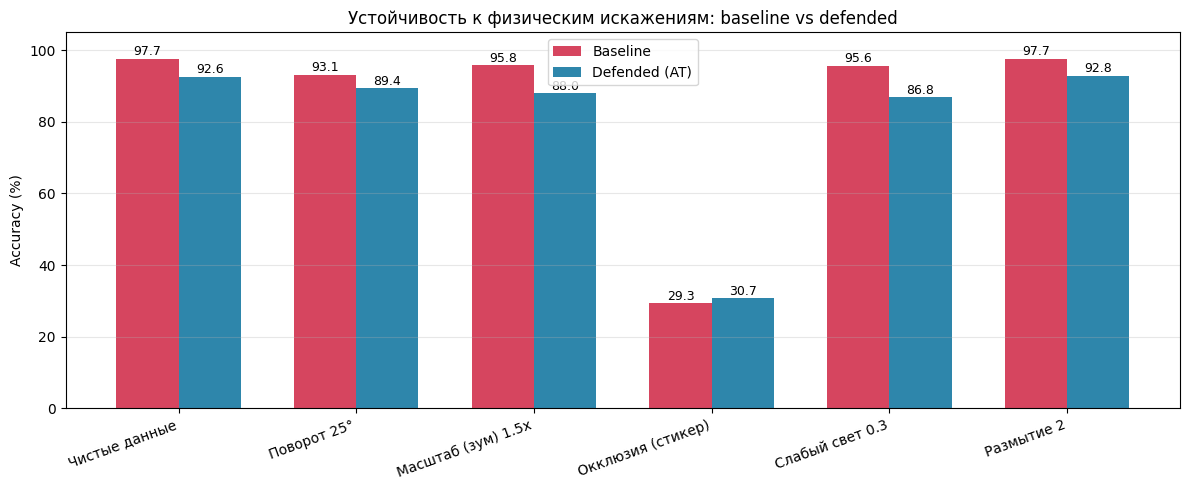

In [ ]:
import pandas as pd
import numpy as np
import torch
import torchvision.transforms.functional as TF
from tqdm.auto import tqdm
from collections import defaultdict
import matplotlib.pyplot as plt

# функция искажения на батче
def apply_physical_distortion_batch(x_batch, name, intensity):
    x = x_batch.clone()
    B, C, H, W = x.shape

    if name == "Поворот":
        x = TF.rotate(x, angle=intensity)

    elif name == "Масштаб (зум)":
        new_h, new_w = int(H / intensity), int(W / intensity)
        top, left = (H - new_h) // 2, (W - new_w) // 2
        x = x[:, :, top:top+new_h, left:left+new_w]
        x = TF.resize(x, (H, W), antialias=False)

    elif name == "Окклюзия (стикер)":
        size = 60
        top, left = (H - size) // 2, (W - size) // 2
        x[:, :, top:top+size, left:left+size] = 0.0

    elif name == "Слабый свет":
        x = x * intensity

    elif name == "Размытие":
        k_size = int(3 * intensity)
        if k_size % 2 == 0:
            k_size += 1
        x = TF.gaussian_blur(x, kernel_size=k_size)

    return x
MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)

def denorm_batch(t):
    return (t * STD + MEAN).clamp(0, 1)

def norm_batch(t):
    return (t - MEAN) / STD

# acc под искажением
@torch.no_grad()
def evaluate_physical(model, loader, distortion_name=None, intensity=None):
    model.eval()
    correct, total = 0, 0
    per_class_correct = defaultdict(int)
    per_class_total = defaultdict(int)

    for x, y in tqdm(loader, desc=f"{distortion_name or 'Clean'}", leave=False):
        x, y = x.to(DEVICE), y.to(DEVICE)

        if distortion_name is not None:
            x = denorm_batch(x)
            x = apply_physical_distortion_batch(x, distortion_name, intensity)
            x = norm_batch(x)

        pred = model(x).argmax(1)
        correct += (pred == y).sum().item()
        total += y.size(0)

        for cls in y.cpu().numpy():
            per_class_total[int(cls)] += 1
        for cls in y[pred == y].cpu().numpy():
            per_class_correct[int(cls)] += 1

    acc = correct / total if total else 0.0
    return acc, dict(per_class_correct), dict(per_class_total)

# прогон по всем искажениям
distortions = [
    ("Поворот 25°", "Поворот", 25),
    ("Масштаб (зум) 1.5x", "Масштаб (зум)", 1.5),
    ("Окклюзия (стикер)", "Окклюзия (стикер)", 1.0),
    ("Слабый свет 0.3", "Слабый свет", 0.3),
    ("Размытие 2", "Размытие", 2.0),
]

results = []
# сначала чистые данные (baseline)
acc_b_clean, corr_b_clean, tot_b_clean = evaluate_physical(baseline_model, val_loader, None, None)
acc_d_clean, corr_d_clean, tot_d_clean = evaluate_physical(defended_model, val_loader, None, None)

results.append({
    "Искажение": "Чистые данные",
    "Baseline acc": acc_b_clean,
    "Defended acc": acc_d_clean,
    "Baseline ASR*": 0.0,
    "Defended ASR*": 0.0,
})

# каждое искажение
per_class_occ = {}
for label, dist_name, intensity in distortions:
    acc_b, corr_b, tot_b = evaluate_physical(baseline_model, val_loader, dist_name, intensity)
    acc_d, corr_d, tot_d = evaluate_physical(defended_model, val_loader, dist_name, intensity)

    # доля примеров, которые были правильны на clean, но сломались под искажением
    asr_b = max(0.0, (acc_b_clean - acc_b) / acc_b_clean) if acc_b_clean > 0 else 0.0
    asr_d = max(0.0, (acc_d_clean - acc_d) / acc_d_clean) if acc_d_clean > 0 else 0.0

    results.append({
        "Искажение": label,
        "Baseline acc": acc_b,
        "Defended acc": acc_d,
        "Baseline ASR*": asr_b,
        "Defended ASR*": asr_d,
    })

    if "Окклюзия" in label:
        per_class_occ = {
            "corr_b": corr_b, "tot_b": tot_b,
            "corr_d": corr_d, "tot_d": tot_d,
        }

df = pd.DataFrame(results)
df["Baseline acc"] = (df["Baseline acc"]  * 100).round(2)
df["Defended acc"] = (df["Defended acc"]  * 100).round(2)
df["Baseline ASR*"] = (df["Baseline ASR*"] * 100).round(2)
df["Defended ASR*"] = (df["Defended ASR*"] * 100).round(2)

print("\nУстойчивость к физ. искажениям:")
display(df)

if per_class_occ:
    print("\nТоп-10 классов, которые ломаются сильнее всего(окклюзия)")
    rows = []
    for cls in range(NUM_CLASSES):
        tb = per_class_occ["tot_b"].get(cls, 0)
        td = per_class_occ["tot_d"].get(cls, 0)
        if tb == 0 and td == 0:
            continue
        # acc по классу под окклюзией
        acc_b_cls = per_class_occ["corr_b"].get(cls, 0) / tb if tb else np.nan
        acc_d_cls = per_class_occ["corr_d"].get(cls, 0) / td if td else np.nan
        # падение относительно clean
        tb_clean = tot_b_clean.get(cls, 0)
        td_clean = tot_d_clean.get(cls, 0)
        acc_b_clean_cls = corr_b_clean.get(cls, 0) / tb_clean if tb_clean else np.nan
        acc_d_clean_cls = corr_d_clean.get(cls, 0) / td_clean if td_clean else np.nan

        drop_b = (acc_b_clean_cls - acc_b_cls) if not np.isnan(acc_b_cls) else np.nan
        drop_d = (acc_d_clean_cls - acc_d_cls) if not np.isnan(acc_d_cls) else np.nan

        rows.append({
            "class": class_names[cls],
            "n_test": tb,
            "clean_acc_b": acc_b_clean_cls,
            "occl_acc_b":  acc_b_cls,
            "drop_b": drop_b,
            "clean_acc_d": acc_d_clean_cls,
            "occl_acc_d":  acc_d_cls,
            "drop_d": drop_d,
        })

    df_occ = pd.DataFrame(rows).dropna(subset=["drop_b"]).sort_values("drop_b", ascending=False)

    df_occ_disp = df_occ.head(10).copy()
    for c in ["clean_acc_b", "occl_acc_b", "drop_b", "clean_acc_d", "occl_acc_d", "drop_d"]:
        df_occ_disp[c] = (df_occ_disp[c] * 100).round(1)
    display(df_occ_disp)

    # Сводка
    print(f"\nСреднее падение accuracy под окклюзией:")
    print(f"Baseline: {df_occ['drop_b'].mean()*100:.2f}%")
    print(f"Defended: {df_occ['drop_d'].mean()*100:.2f}%")
    n_broken_b = (df_occ["drop_b"] > 0.5).sum()
    n_broken_d = (df_occ["drop_d"] > 0.5).sum()
    print(f"Классов с падением >50%: baseline={n_broken_b}, defended={n_broken_d}")

labels = df["Искажение"].tolist()
x = np.arange(len(labels))
w = 0.35

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(x - w/2, df["Baseline acc"], w, label="Baseline", color="#D6455F")
ax.bar(x + w/2, df["Defended acc"], w, label="Defended (AT)", color="#2E86AB")

for i, (b, d) in enumerate(zip(df["Baseline acc"], df["Defended acc"])):
    ax.text(i - w/2, b + 1, f"{b:.1f}", ha='center', fontsize=9)
    ax.text(i + w/2, d + 1, f"{d:.1f}", ha='center', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=20, ha='right')
ax.set_ylabel("Accuracy (%)")
ax.set_title("Устойчивость к физическим искажениям: baseline vs defended")
ax.set_ylim(0, 105)
ax.grid(axis='y', alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()